# Data Visualization

This script contains the script to reproduce all data demonstration and visualizations in the paper.

In [1]:
import json
import re
from pathlib import Path

import pandas as pd
import numpy as np
from scipy.stats import wilcoxon, spearmanr, pearsonr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FormatStrFormatter

# DISENTANGLING THE EFFECTS OF MATCHER DESIGN

## Effect of Pre-training Objective

In [2]:
DATASETS = ["ab", "ag", "ds", "rt", "sh", "sr", "wa", "w20", "w80"]
HETERO = {"sh", "sr"}
STRUCTURED = [d for d in DATASETS if d not in HETERO]
PARADIGMS = ["bi_encoder", "cross_encoder", "generative"]
VARIANTS = ["instruct", "base", "emb"]

In [3]:
# load data
RESULTS_ROOT = Path("../results")
OUT_PATH = Path("data/rq1_raw_data.csv")

MODEL_META = {
    "Qwen3-0.6B": ("instruct", "0.6b"),
    "Qwen3-0.6B-Base": ("base", "0.6b"),
    "Qwen3-Embedding-0.6B": ("emb", "0.6b"),
    "Qwen3-4B": ("instruct", "4b"),
    "Qwen3-4B-Base": ("base", "4b"),
    "Qwen3-Embedding-4B": ("emb", "4b"),
    "Qwen3-8B": ("instruct", "8b"),
    "Qwen3-8B-Base": ("base", "8b"),
    "Qwen3-Embedding-8B": ("emb", "8b"),
}

RUN_RE = re.compile(r"(.+)_seed(\d+)$")

In [4]:
rows = []
for split_dir in sorted(RESULTS_ROOT.glob("main_*")):
    for paradigm in PARADIGMS:
        p_dir = split_dir / paradigm
        if not p_dir.exists():
            continue
        for ds_dir in p_dir.iterdir():
            if ds_dir.name not in DATASETS:
                continue
            for run_dir in ds_dir.iterdir():
                m = RUN_RE.match(run_dir.name)
                if not m:
                    continue
                model, seed = m.group(1), m.group(2)
                if model not in MODEL_META:
                    continue
                variant, scale = MODEL_META[model]
                log = run_dir / "training_log.json"
                if not log.exists():
                    continue
                with open(log) as f:
                    d = json.load(f)
                rows.append(
                    {
                        "paradigm": paradigm,
                        "variant": variant,
                        "scale": scale,
                        "dataset": ds_dir.name,
                        "seed": seed,
                        "f1": d.get("test_f1"),
                        "precision": d.get("test_precision"),
                        "recall": d.get("test_recall"),
                    }
                )

df = pd.DataFrame(rows)

# human-readable ordering
df["paradigm"] = pd.Categorical(df["paradigm"], PARADIGMS, ordered=True)
df["variant"] = pd.Categorical(df["variant"], ["instruct", "base", "emb"], ordered=True)
df["scale"] = pd.Categorical(df["scale"], ["0.6b", "4b", "8b"], ordered=True)
df["dataset"] = pd.Categorical(df["dataset"], DATASETS, ordered=True)
df["_seed"] = df["seed"].astype(int)
df = df.sort_values(["paradigm", "variant", "scale", "dataset", "_seed"]).drop(
    columns="_seed"
)

# round metrics
for c in ["f1", "precision", "recall"]:
    df[c] = df[c].round(4)

df.to_csv(OUT_PATH, index=False)
print(f"wrote {OUT_PATH}: {len(df)} rows (expected 1215)")

wrote data/rq1_raw_data.csv: 1215 rows (expected 1215)


### Checkpoint-variant table


In [5]:
df = pd.read_csv("data/rq1_raw_data.csv")

# per (paradigm, dataset, variant): mean F1 pooled over scale AND seed
ds_mean = df.groupby(["paradigm", "dataset", "variant"]).f1.mean().reset_index()

In [6]:
def best_variant(par, datasets):
    """argmax-avg variant over a given set of datasets."""
    sub = ds_mean[(ds_mean.paradigm == par) & (ds_mean.dataset.isin(datasets))]
    avg = sub.groupby("variant").f1.mean()
    return avg.idxmax(), avg.max()

In [7]:
for par in PARADIGMS:
    piv = (
        ds_mean[ds_mean.paradigm == par]
        .pivot(index="dataset", columns="variant", values="f1")
        .loc[DATASETS]
    )  # rows=9 datasets, cols=3 variants

    avg = {v: piv[v].mean() for v in VARIANTS}  # macro avg F1
    wins = {v: int((piv.idxmax(axis=1) == v).sum()) for v in VARIANTS}  # /9

    ordered = sorted(VARIANTS, key=lambda v: avg[v], reverse=True)
    best, second = ordered[0], ordered[1]
    delta = (avg[best] - avg[second]) * 100  # pp
    _, p = wilcoxon(piv[best], piv[second])

    bs, _ = best_variant(par, STRUCTURED)
    bh, _ = best_variant(par, list(HETERO))

    print(f"\n### {par}")
    for v in VARIANTS:
        print(f"  {v:9}  F1={avg[v]*100:5.1f}%   wins={wins[v]}/9")
    print(f"  best={best}  2nd={second}  Delta={delta:+.1f}pp  p={p:.3f}")
    print(f"  best on structured={bs}   best on heterogeneous={bh}")


### bi_encoder
  instruct   F1= 53.7%   wins=0/9
  base       F1= 57.4%   wins=0/9
  emb        F1= 77.7%   wins=9/9
  best=emb  2nd=base  Delta=+20.3pp  p=0.004
  best on structured=emb   best on heterogeneous=emb

### cross_encoder
  instruct   F1= 82.5%   wins=4/9
  base       F1= 83.7%   wins=5/9
  emb        F1= 81.7%   wins=0/9
  best=base  2nd=instruct  Delta=+1.2pp  p=0.652
  best on structured=base   best on heterogeneous=base

### generative
  instruct   F1= 85.9%   wins=0/9
  base       F1= 86.3%   wins=7/9
  emb        F1= 86.4%   wins=2/9
  best=emb  2nd=base  Delta=+0.0pp  p=0.570
  best on structured=base   best on heterogeneous=emb


### Probe for the Pretrained Representation

In [8]:
GEO_CSV = Path("../results/geometry_probe_0.6b.csv")
RAW_CSV = Path("data/rq1_raw_data.csv")

geo = pd.read_csv(GEO_CSV)
raw = pd.read_csv(RAW_CSV)
f1 = (
    raw[(raw.paradigm == "bi_encoder") & (raw.scale == "0.6b")]
    .groupby(["dataset", "variant"])
    .f1.mean()
    .reset_index()
)
m = geo.merge(f1, on=["dataset", "variant"])
assert len(m) == 27, f"expected 27 points, got {len(m)}"

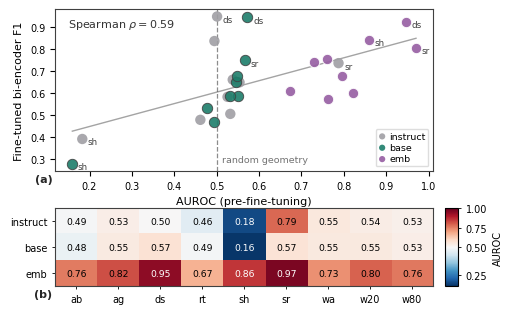

In [9]:
COLOR = {
    "instruct": "#a09fa4",
    "base": "#1d7d6a",
    "emb": "#965da2",
}

# ── Combined Figure: geometry scatter + AUROC heatmap ───────────────────────
r_s, p_s = spearmanr(m.auroc, m.f1)
r_p, _ = pearsonr(m.auroc, m.f1)

piv = geo.pivot(index="variant", columns="dataset", values="auroc").loc[
    VARIANTS, DATASETS
]

fig = plt.figure(figsize=(5.2, 3.6))
gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    width_ratios=[1.0, 0.035],
    height_ratios=[2.45, 1.18],
    hspace=0.31,
    wspace=0.06,
)

ax = fig.add_subplot(gs[0, 0])
ax_h = fig.add_subplot(gs[1, 0])
cax = fig.add_subplot(gs[1, 1])

# ── (a) Scatter ─────────────────────────────────────────────────────────────
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)
    spine.set_color("0.25")

ax.grid(False)

coef = np.polyfit(m.auroc, m.f1, 1)
xfit = np.linspace(m.auroc.min(), m.auroc.max(), 100)
yfit = coef[0] * xfit + coef[1]
ax.plot(xfit, yfit, color="0.35", lw=1.0, alpha=0.55, zorder=1)

EDGE = {
    "embedding": "white",
    "base": "0.25",
    "instruct": "none",
}

LW = {
    "embedding": 0.85,
    "base": 0.65,
    "instruct": 0.0,
}

for v in VARIANTS:
    s = m[m.variant == v]
    ax.scatter(
        s.auroc,
        s.f1,
        c=COLOR[v],
        label=v,
        marker="o",
        s=56,
        edgecolor=EDGE.get(v, "white"),
        linewidth=LW.get(v, 0.75),
        alpha=0.90,
        zorder=3,
    )

for _, r in m.iterrows():
    if r.dataset in ("sh", "sr", "ds"):
        ax.annotate(
            r.dataset,
            (r.auroc, r.f1),
            fontsize=6.3,
            xytext=(4, -4),
            textcoords="offset points",
            color="0.25",
        )

ax.axvline(0.5, ls="--", color="0.55", lw=0.9, zorder=0)

ax.annotate(
    "random geometry",
    xy=(0.5, 0.045),
    xycoords=("data", "axes fraction"),
    xytext=(4, 0),
    textcoords="offset points",
    fontsize=6.8,
    color="0.45",
    ha="left",
    va="bottom",
)

ax.text(
    0.035,
    0.95,
    rf"Spearman $\rho={r_s:.2f}$",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=8,
    color="0.2",
)

ax.annotate(
    "(a)",
    xy=(0, 0),
    xycoords="axes fraction",
    xytext=(-2, -2),
    textcoords="offset points",
    ha="right",
    va="top",
    fontsize=8,
    fontweight="bold",
    color="0.15",
    clip_on=False,
)

ax.set_xlabel("AUROC (pre-fine-tuning)", fontsize=8)
ax.set_ylabel("Fine-tuned bi-encoder F1", fontsize=8)
ax.tick_params(axis="both", labelsize=7)

leg = ax.legend(
    title="",
    loc="lower right",
    fontsize=6.8,
    frameon=True,
    framealpha=0.88,
    facecolor="white",
    edgecolor="0.85",
    borderpad=0.30,
    labelspacing=0.25,
    handletextpad=0.35,
    handlelength=0.8,
)

for h in leg.legend_handles:
    if hasattr(h, "set_sizes"):
        h.set_sizes([20])  # marker area shown in the legend
        h.set_edgecolor("none")  # no border on legend markers
        h.set_linewidth(0.0)


# ── (b) Heatmap ─────────────────────────────────────────────────────────────
im = ax_h.imshow(
    piv.values,
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vcenter=0.5, vmin=0.15, vmax=1.0),
    aspect="auto",
)

for spine in ax_h.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)
    spine.set_color("0.25")

ax_h.set_xticks(range(len(DATASETS)))
ax_h.set_xticklabels(DATASETS, fontsize=7)
ax_h.set_yticks(range(len(VARIANTS)))
ax_h.set_yticklabels(VARIANTS, fontsize=7)
ax_h.tick_params(axis="both", length=2, width=0.6)

for i in range(len(VARIANTS)):
    for j in range(len(DATASETS)):
        val = piv.values[i, j]
        ax_h.text(
            j,
            i,
            f"{val:.2f}",
            ha="center",
            va="center",
            fontsize=6.7,
            color="white" if (val < 0.35 or val > 0.85) else "black",
        )

ax_h.annotate(
    "(b)",
    xy=(0, 0),
    xycoords="axes fraction",
    xytext=(-2, -2),
    textcoords="offset points",
    ha="right",
    va="top",
    fontsize=8,
    fontweight="bold",
    color="0.15",
    clip_on=False,
)

cb = fig.colorbar(im, cax=cax)
cb.set_label("AUROC", fontsize=7)
cb.ax.tick_params(labelsize=7, length=2, width=0.6)

fig.savefig("figures/rq1_f4_geometry_combined.pdf", bbox_inches="tight")

### Full-FT ablation

In [10]:
RESULTS = Path("../results")
FULLFT_DIR = RESULTS / "ablation_fullft" / "bi_encoder"  # full-FT instruct & base
LORA_DIR = RESULTS / "main_0.6b" / "bi_encoder"  # emb+LoRA (main runs)
DATASETS = ["ab", "sh", "sr"]

FULLFT_MODELS = {
    "Qwen3-0.6B": "Full FT instruct",  # instruct checkpoint
    "Qwen3-0.6B-Base": "Full FT base",
}  # base checkpoint
LORA_MODEL = "Qwen3-Embedding-0.6B"


def mean_test_f1(ds_dir: Path, model_prefix: str) -> float:
    """Mean test F1 over all seed runs of `model_prefix` in `ds_dir`."""
    vals = []
    for run in ds_dir.glob(
        f"{model_prefix}_seed*"
    ):  # '_' distinguishes 0.6B vs 0.6B-Base
        log = run / "training_log.json"
        if log.exists():
            vals.append(json.load(open(log))["test_f1"])
    return sum(vals) / len(vals) if vals else float("nan")


rows = []
for ds in DATASETS:
    row = {"Dataset": ds}
    for model, label in FULLFT_MODELS.items():
        row[label] = mean_test_f1(FULLFT_DIR / ds, model)
    row["emb+LoRA"] = mean_test_f1(LORA_DIR / ds, LORA_MODEL)
    rows.append(row)

df = pd.DataFrame(rows).set_index("Dataset")
cols = ["Full FT instruct", "Full FT base", "emb+LoRA"]

# emit markdown, bolding the row-max
print("| Dataset | Full FT instruct | Full FT base | emb+LoRA |")
print("|---------|-----------------|--------------|----------|")
for ds, r in df.iterrows():
    best = r[cols].idxmax()
    cells = [f"**{r[c]:.3f}**" if c == best else f"{r[c]:.3f}" for c in cols]
    print(f"| {ds} | {cells[0]} | {cells[1]} | {cells[2]} |")

| Dataset | Full FT instruct | Full FT base | emb+LoRA |
|---------|-----------------|--------------|----------|
| ab | 0.750 | 0.754 | **0.757** |
| sh | 0.411 | 0.329 | **0.840** |
| sr | 0.737 | 0.668 | **0.805** |


## Effect of Joint Pair Encoding

In [11]:
BASELINE_PATH = Path("../results/baselines")
OUT_PATH = "data/rq2_baselines_raw_data.csv"

DATASETS = ["ab", "ag", "ds", "rt", "sh", "sr", "wa", "w20", "w80"]
SEEDS = [42, 123, 456, 789, 2024]

# alias -> Ditto's full dataset dir name
DITTO_NAME = {
    "ab": "abt_buy",
    "ag": "amazon_google",
    "ds": "dblp_scholar",
    "rt": "rel-text",
    "sh": "semi-heter",
    "sr": "semi-rel",
    "wa": "walmart_amazon",
    "w20": "wdc20",
    "w80": "wdc80",
}


def prf(preds, labels):
    """Binary precision/recall/F1 for the positive (match) class."""
    tp = sum(p == 1 and l == 1 for p, l in zip(preds, labels))
    fp = sum(p == 1 and l == 0 for p, l in zip(preds, labels))
    fn = sum(p == 0 and l == 1 for p, l in zip(preds, labels))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return prec, rec, f1


def load(path):
    with open(path) as f:
        return json.load(f)

In [12]:
rows = []

# --- Ditto: metrics read straight from the run file ---
for ds in DATASETS:
    for seed in SEEDS:
        p = BASELINE_PATH / "ditto" / DITTO_NAME[ds] / f"results_run{seed}.json"
        if not p.exists():
            continue
        d = load(p)
        rows.append(
            {
                "method": "ditto",
                "dataset": ds,
                "seed": seed,
                "f1": round(d["f1"], 4),
                "precision": round(d["precision"], 4),
                "recall": round(d["recall"], 4),
            }
        )

# --- SBERT: compute P/R/F1 from stored predictions ---
for ds in DATASETS:
    for seed in SEEDS:
        p = (
            BASELINE_PATH
            / "sbert"
            / ds
            / f"stsb-roberta-base-v2_seed{seed}"
            / "test_results.json"
        )
        if not p.exists():
            continue
        pl = load(p)["predictions"]
        prec, rec, f1 = prf([x["pred"] for x in pl], [x["label"] for x in pl])
        rows.append(
            {
                "method": "sbert",
                "dataset": ds,
                "seed": seed,
                "f1": round(f1, 4),
                "precision": round(prec, 4),
                "recall": round(rec, 4),
            }
        )

# --- GPT-4.1-mini: zero-shot, single run (no seed) ---
for ds in DATASETS:
    p = BASELINE_PATH / "openai" / ds / "gpt-4.1-mini" / "training_log.json"
    if not p.exists():
        continue
    d = load(p)
    rows.append(
        {
            "method": "gpt-4.1-mini",
            "dataset": ds,
            "seed": "na",
            "f1": round(d["test_f1"], 4),
            "precision": round(d["test_precision"], 4),
            "recall": round(d["test_recall"], 4),
        }
    )

df = pd.DataFrame(
    rows, columns=["method", "dataset", "seed", "f1", "precision", "recall"]
)
df.to_csv(OUT_PATH, index=False)
print(f"Wrote {len(df)} rows -> {OUT_PATH}")

Wrote 99 rows -> data/rq2_baselines_raw_data.csv


In [13]:
RESULTS_ROOT = Path("../results")
OUT_PATH = "data/rq2_raw_data.csv"

SCALES = ["0.6b", "4b", "8b"]
SCALE_UC = {"0.6b": "0.6B", "4b": "4B", "8b": "8B"}  # dir suffix casing
DATASETS = ["ab", "ag", "ds", "rt", "sh", "sr", "wa", "w20", "w80"]
SEEDS = [42, 123, 456, 789, 2024]

# best variant per paradigm -> model-name template ({u} = upper-case scale)
PARADIGMS = {
    "bi_encoder": ("emb", "Qwen3-Embedding-{u}"),
    "cross_encoder": ("base", "Qwen3-{u}-Base"),
    "generative": ("base", "Qwen3-{u}-Base"),
}


def load(path: Path) -> dict:
    with open(path) as f:
        return json.load(f)

In [14]:
rows = []
missing = []
for paradigm, (variant, tmpl) in PARADIGMS.items():
    for scale in SCALES:
        model = tmpl.format(u=SCALE_UC[scale])
        for dataset in DATASETS:
            for seed in SEEDS:
                log = (
                    RESULTS_ROOT
                    / f"main_{scale}"
                    / paradigm
                    / dataset
                    / f"{model}_seed{seed}"
                    / "training_log.json"
                )
                if not log.exists():
                    missing.append(str(log.relative_to(PROJECT_ROOT)))
                    continue
                d = load(log)
                rows.append(
                    {
                        "paradigm": paradigm,
                        "variant": variant,
                        "scale": scale,
                        "dataset": dataset,
                        "seed": seed,
                        "f1": round(d["test_f1"], 4),
                        "precision": round(d["test_precision"], 4),
                        "recall": round(d["test_recall"], 4),
                    }
                )

if not rows:
    raise RuntimeError(f"No runs found under {RESULTS_ROOT} — check paths.")
if missing:
    print(f"WARNING: {len(missing)} missing run(s), e.g. {missing[:3]}")

df = pd.DataFrame(rows)
# stable ordering for reproducible diffs
df["paradigm"] = pd.Categorical(df["paradigm"], list(PARADIGMS), ordered=True)
df["scale"] = pd.Categorical(df["scale"], SCALES, ordered=True)
df["dataset"] = pd.Categorical(df["dataset"], DATASETS, ordered=True)
df = df.sort_values(["paradigm", "scale", "dataset", "seed"]).reset_index(drop=True)

df.to_csv(OUT_PATH, index=False)
print(f"Wrote {len(df)} rows -> {OUT_PATH}")

Wrote 405 rows -> data/rq2_raw_data.csv


### Per-dataset test F1 scores and scaling gains across matching architectures

In [15]:
RAW_CSV = "data/rq2_raw_data.csv"
BASE_CSV = "data/rq2_baselines_raw_data.csv"

SCALES = ["0.6b", "4b", "8b"]
DATASETS = ["ab", "ag", "ds", "rt", "sh", "sr", "wa", "w20", "w80"]

# paradigm -> (table title, baseline method, baseline column header)
PARADIGMS = {
    "bi_encoder": ("Bi-encoder (Embedding)", "sbert", "SBERT"),
    "cross_encoder": ("Cross-encoder (Base)", "ditto", "Ditto"),
    "generative": ("Generative (Base)", "gpt-4.1-mini", "GPT-4.1-mini"),
}


def cell(mean, std):  # 0.725, 0.003 -> "72.5±0.3"; std NaN -> no ±
    if pd.isna(mean):
        return "—"
    return f"{mean * 100:.1f}" if pd.isna(std) else f"{mean * 100:.1f}±{std * 100:.1f}"


def dlt(x):  # signed delta in pp, unicode minus
    return f"{'+' if x >= 0 else '−'}{abs(x) * 100:.1f}"


df = pd.read_csv(RAW_CSV)
bdf = pd.read_csv(BASE_CSV)

# baseline stats: dataset x method
bg = bdf.groupby(["dataset", "method"])["f1"]
bmean = bg.mean().unstack("method")
bstd = bg.std(ddof=1).unstack("method")

In [16]:
for paradigm, (title, bmethod, bhdr) in PARADIGMS.items():
    sub = df[df.paradigm == paradigm]
    g = sub.groupby(["dataset", "scale"])["f1"]
    mean = g.mean().unstack("scale").reindex(index=DATASETS, columns=SCALES)
    std = g.std(ddof=1).unstack("scale").reindex(index=DATASETS, columns=SCALES)

    # baseline column for this paradigm
    bmn = bmean[bmethod].reindex(DATASETS)
    bsd = bstd[bmethod].reindex(DATASETS)

    # avg row: macro-avg of dataset means; std = mean of per-dataset seed stds
    mean.loc["avg"] = mean.mean()
    std.loc["avg"] = std.mean()
    bmn.loc["avg"] = bmn.mean()
    bsd.loc["avg"] = bsd.mean()

    print(f"### {title}\n")
    print(f"| Dataset | {bhdr} | 0.6B | 4B | 8B | Δ(0.6→4) | Δ(4→8) | Δ(0.6→8) |")
    print("|---------|------|------|----|----|----------|--------|----------|")
    for ds in mean.index:
        a, b, c = mean.loc[ds, "0.6b"], mean.loc[ds, "4b"], mean.loc[ds, "8b"]
        sa, sb, sc = std.loc[ds, "0.6b"], std.loc[ds, "4b"], std.loc[ds, "8b"]
        bold = (lambda s: f"**{s}**") if ds == "avg" else (lambda s: s)
        print(
            f"| {bold(ds)} | {bold(cell(bmn.loc[ds], bsd.loc[ds]))} | "
            f"{bold(cell(a, sa))} | {bold(cell(b, sb))} | {bold(cell(c, sc))} | "
            f"{bold(dlt(b - a))} | {bold(dlt(c - b))} | {bold(dlt(c - a))} |"
        )
    print()

### Bi-encoder (Embedding)

| Dataset | SBERT | 0.6B | 4B | 8B | Δ(0.6→4) | Δ(4→8) | Δ(0.6→8) |
|---------|------|------|----|----|----------|--------|----------|
| ab | 87.5±0.2 | 75.7±0.4 | 88.0±0.3 | 91.1±0.9 | +12.3 | +3.1 | +15.4 |
| ag | 73.7±0.6 | 60.0±0.5 | 72.0±0.6 | 76.3±0.5 | +12.0 | +4.3 | +16.3 |
| ds | 93.3±0.1 | 92.4±0.4 | 93.9±0.9 | 95.3±0.4 | +1.5 | +1.5 | +3.0 |
| rt | 61.7±0.8 | 60.9±0.6 | 67.5±0.6 | 72.0±0.7 | +6.6 | +4.6 | +11.2 |
| sh | 55.3±0.5 | 84.0±1.0 | 86.7±0.7 | 86.0±1.7 | +2.6 | −0.7 | +1.9 |
| sr | 82.2±0.7 | 80.5±0.6 | 79.9±0.4 | 85.6±1.7 | −0.6 | +5.7 | +5.1 |
| wa | 77.6±0.6 | 73.9±0.6 | 82.0±1.2 | 81.9±0.5 | +8.1 | −0.2 | +8.0 |
| w20 | 67.9±0.5 | 67.9±0.6 | 75.0±0.9 | 76.2±0.3 | +7.1 | +1.2 | +8.3 |
| w80 | 56.6±1.0 | 57.3±0.2 | 66.3±1.1 | 69.4±0.9 | +9.0 | +3.1 | +12.2 |
| **avg** | **72.9±0.6** | **72.5±0.5** | **79.0±0.8** | **81.5±0.8** | **+6.5** | **+2.5** | **+9.0** |

### Cross-encoder (Base)

| Dataset | Ditto | 0.6B | 4B | 8B | Δ(0.6→4) | Δ

### Heatmap for scaling gains

In [17]:
from matplotlib.patches import Rectangle

csv_path = "data/rq2_raw_data.csv"
metric = "f1"

scale_order = ["0.6b", "4b", "8b"]
paradigm_order = ["bi_encoder", "cross_encoder", "generative"]

paradigm_display = {
    "bi_encoder": "Bi-encoder",
    "cross_encoder": "Cross-encoder",
    "generative": "Generative",
}

variant_filter = {
    "bi_encoder": "emb",
    "cross_encoder": "base",
    "generative": "base",
}

delta_columns = ["0.6B→4B", "4B→8B", "0.6B→8B"]
transition_order = ["0.6B→4B", "4B→8B"]

dataset_order = [
    "ab",
    "ag",
    "ds",
    "rt",
    "sh",
    "sr",
    "wa",
    "w20",
    "w80",
    "AVG",
]
dataset_labels = dataset_order

In [18]:
# ── Load and preprocess ──────────────────────────────────────────────────────
df = pd.read_csv(csv_path)

df["scale"] = df["scale"].astype(str).str.lower().str.strip()
df["paradigm"] = df["paradigm"].astype(str).str.strip()
df["variant"] = df["variant"].astype(str).str.strip()
df["dataset"] = df["dataset"].astype(str).str.lower().str.strip()

df = df[
    df.apply(
        lambda r: r["variant"] == variant_filter.get(r["paradigm"], r["variant"]),
        axis=1,
    )
].copy()

missing_paradigms = sorted(set(paradigm_order) - set(df["paradigm"].unique()))
if missing_paradigms:
    raise ValueError(f"Missing paradigms in filtered data: {missing_paradigms}")

In [19]:
# ── Compute scale deltas by seed ─────────────────────────────────────────────
seed_wide = df.pivot_table(
    index=["paradigm", "dataset", "seed"],
    columns="scale",
    values=metric,
    aggfunc="mean",
).reset_index()

missing_scales = [scale for scale in scale_order if scale not in seed_wide.columns]
if missing_scales:
    raise ValueError(f"Missing scale columns after pivot: {missing_scales}")

seed_wide["0.6B→4B"] = (seed_wide["4b"] - seed_wide["0.6b"]) * 100

seed_wide["4B→8B"] = (seed_wide["8b"] - seed_wide["4b"]) * 100

seed_wide["0.6B→8B"] = (seed_wide["8b"] - seed_wide["0.6b"]) * 100

# ── Dataset-level means and standard deviations ─────────────────────────────
delta_mean = seed_wide.groupby(["paradigm", "dataset"], as_index=False)[
    delta_columns
].mean()

delta_std = seed_wide.groupby(["paradigm", "dataset"], as_index=False)[
    delta_columns
].std()

In [20]:
# ── Macro-average across datasets, computed within each seed ────────────────
avg_seed = seed_wide.groupby(["paradigm", "seed"], as_index=False)[delta_columns].mean()

avg_seed["dataset"] = "AVG"

avg_mean = avg_seed.groupby(["paradigm", "dataset"], as_index=False)[
    delta_columns
].mean()

avg_std = avg_seed.groupby(["paradigm", "dataset"], as_index=False)[delta_columns].std()

delta_mean = pd.concat(
    [
        delta_mean[["paradigm", "dataset"] + delta_columns],
        avg_mean[["paradigm", "dataset"] + delta_columns],
    ],
    ignore_index=True,
)

delta_std = pd.concat(
    [
        delta_std[["paradigm", "dataset"] + delta_columns],
        avg_std[["paradigm", "dataset"] + delta_columns],
    ],
    ignore_index=True,
)

In [21]:
# ── Validate dataset ordering ────────────────────────────────────────────────
available_datasets = set(delta_mean["dataset"].unique())

missing_from_order = sorted(available_datasets - set(dataset_order))
missing_from_data = sorted(set(dataset_order) - available_datasets)

if missing_from_order:
    print(
        "Warning: datasets present in data but absent from "
        f"dataset_order: {missing_from_order}"
    )

if missing_from_data:
    print(
        "Warning: datasets in dataset_order but absent from "
        f"data: {missing_from_data}"
    )

In [22]:
# ── Shared diverging normalization ───────────────────────────────────────────
all_values = delta_mean[transition_order].to_numpy().ravel()

COLOR_VMAX = 15.0
vmax = COLOR_VMAX if COLOR_VMAX is not None else np.nanmax(np.abs(all_values))

if vmax == 0 or np.isnan(vmax):
    vmax = 1e-6

norm = TwoSlopeNorm(
    vmin=-vmax,
    vcenter=0.0,
    vmax=vmax,
)

# Match the original heatmap's normalized text-color cutoffs:
# dark blue region  → white
# central/light area → black
# dark red region   → white
TEXT_WHITE_LOW_NORM = 2.0 / 7.0  # ≈ 0.286
TEXT_WHITE_HIGH_NORM = 0.85


def heatmap_text_color(value):
    """Choose annotation color using the normalized colormap position."""
    if np.isnan(value):
        return "0.35"

    normalized_value = norm(value)

    if (
        normalized_value < TEXT_WHITE_LOW_NORM
        or normalized_value > TEXT_WHITE_HIGH_NORM
    ):
        return "white"

    return "black"

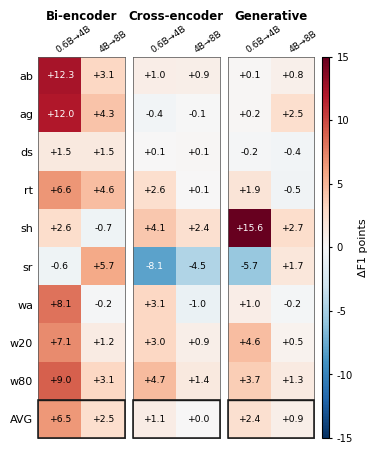

In [23]:
# ── Typography ───────────────────────────────────────────────────────────────
TITLE_FS = 8.5
YTICK_FS = 8.0

# Same numeric annotation size and default font as the first heatmap.
CELL_MAIN_FS = 6.7

CBAR_LABEL_FS = 8.0
CBAR_TICK_FS = 7.2

# ── Figure layout ────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(3.75, 4.95))

# gs = fig.add_gridspec(
#     nrows=1,
#     ncols=4,
#     width_ratios=[1.0, 1.0, 1.0, 0.075],
#     wspace=0.055,
# )
gs = fig.add_gridspec(
    nrows=1,
    ncols=4,
    width_ratios=[1.0, 1.0, 1.0, 0.075],
    wspace=0.12,
)

axes = [fig.add_subplot(gs[0, i]) for i in range(len(paradigm_order))]

cax = fig.add_subplot(gs[0, 3])

# ── Heatmaps ─────────────────────────────────────────────────────────────────
for ax_idx, (ax, paradigm) in enumerate(zip(axes, paradigm_order)):
    mean_sub = (
        delta_mean[delta_mean["paradigm"] == paradigm]
        .set_index("dataset")
        .reindex(dataset_order)
    )

    mean_mat = mean_sub[transition_order].to_numpy()

    im = ax.imshow(
        mean_mat,
        aspect="auto",
        cmap="RdBu_r",
        norm=norm,
        interpolation="nearest",
    )

    ax.set_title(
        paradigm_display.get(paradigm, paradigm),
        fontsize=TITLE_FS,
        fontweight="semibold",
        pad=3,
    )

    ax.set_xticks(np.arange(len(transition_order)))
    ax.set_xticklabels(
        transition_order,
        fontsize=6.6,
        rotation=35,
        ha="left",
        rotation_mode="anchor",
    )

    ax.xaxis.tick_top()
    ax.tick_params(
        axis="x",
        top=True,
        labeltop=True,
        bottom=False,
        labelbottom=False,
        length=0,
        pad=1.5,
    )

    ax.set_yticks(np.arange(len(dataset_order)))

    if ax_idx == 0:
        ax.set_yticklabels(
            dataset_labels,
            fontsize=YTICK_FS,
        )
    else:
        ax.set_yticklabels([])

    # Numeric annotations
    for i in range(mean_mat.shape[0]):
        for j in range(mean_mat.shape[1]):
            mean_value = mean_mat[i, j]

            main_label = "NA" if np.isnan(mean_value) else f"{mean_value:+.1f}"

            ax.text(
                j,
                i,
                main_label,
                ha="center",
                va="center",
                fontsize=CELL_MAIN_FS,
                fontweight="normal",
                color=heatmap_text_color(mean_value),
            )

    ax.tick_params(axis="both", length=0)

    # Separator above AVG
    ax.axhline(
        len(dataset_order) - 1.5,
        color="0.10",
        linewidth=1.0,
    )

    # Border around AVG row
    avg_i = dataset_order.index("AVG")

    ax.add_patch(
        Rectangle(
            (-0.5, avg_i - 0.5),
            len(transition_order),
            1.0,
            fill=False,
            edgecolor="0.10",
            linewidth=1.15,
            zorder=4,
            clip_on=False,
        )
    )

    # Apply spine styling to every heatmap axis
    for spine in ax.spines.values():
        spine.set_linewidth(0.55)
        spine.set_color("0.35")

# ── Colorbar ─────────────────────────────────────────────────────────────────
cbar = fig.colorbar(im, cax=cax)

cbar.set_label(
    "ΔF1 points",
    fontsize=CBAR_LABEL_FS,
)

cbar.ax.tick_params(
    labelsize=CBAR_TICK_FS,
    length=2,
)

cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.0f"))

# ── Save ─────────────────────────────────────────────────────────────────────
plt.savefig(
    "figures/scale_delta_heatmap.pdf",
    bbox_inches="tight",
)

plt.show()

## Effect of Matching Prediction Formulation

In [24]:
RAW_CSV = "data/rq2_raw_data.csv"

SCALES = ["0.6b", "4b", "8b"]
AVG_DATASETS = ["ab", "ag", "ds", "rt", "wa", "w20", "w80"]

PARADIGMS = {
    "cross_encoder": "Cross-encoder (Base)",
    "generative": "Generative (Base)",
}

df = pd.read_csv(RAW_CSV)

for paradigm, title in PARADIGMS.items():
    mean = (
        df[(df["paradigm"] == paradigm) & (df["dataset"].isin(AVG_DATASETS))]
        .groupby(["dataset", "scale"])["f1"]
        .mean()
        .unstack("scale")
        .reindex(columns=SCALES)
        .mean(axis=0)
    )

    print(f"{title}:")
    for scale in SCALES:
        print(f"  {scale}: {mean[scale] * 100:.1f}")

Cross-encoder (Base):
  0.6b: 84.4
  4b: 86.4
  8b: 86.7
Generative (Base):
  0.6b: 84.7
  4b: 86.3
  8b: 86.9


In [25]:
import matplotlib as mpl

mpl.rcdefaults()

# ── Load data ────────────────────────────────────────────────────────────────
df = pd.read_csv("data/rq2_raw_data.csv")

LEFT_DATASETS = ["ab", "ag", "ds", "rt", "wa", "w20", "w80"]
SPECIAL_DATASETS = ["sh", "sr"]
SCALES = ["0.6b", "4b", "8b"]
PARADIGMS = ["cross_encoder", "generative"]

LABEL = {
    "cross_encoder": "Cross.",
    "generative": "Gen.",
}

COLOR = {
    "cross_encoder": "#0072B2",
    "generative": "#D55E00",
}

MARKER = {
    "cross_encoder": "s",
    "generative": "^",
}

SCALE_LABEL = {
    "0.6b": "0.6B",
    "4b": "4B",
    "8b": "8B",
}

SCALE_COLOR = {
    "0.6b": "#B8B8B8",
    "4b": "#7F7F7F",
    "8b": "#464646",
}

df = df[df["paradigm"].isin(PARADIGMS)].copy()

In [26]:
# ── Data for panel (a): paired delta ─────────────────────────────────────────
paired = (
    df[df["dataset"].isin(LEFT_DATASETS) & df["scale"].isin(SCALES)]
    .pivot_table(
        index=["dataset", "scale", "seed"],
        columns="paradigm",
        values="f1",
        aggfunc="mean",
    )
    .dropna(subset=PARADIGMS)
    .reset_index()
)

# Positive: Generative performs better.
# Negative: Cross-encoder performs better.
paired["delta_f1"] = (paired["generative"] - paired["cross_encoder"]) * 100

bar_data = paired.groupby(
    ["dataset", "scale"],
    as_index=False,
)["delta_f1"].mean()

In [27]:
# ── Data for panels (b) and (c) ──────────────────────────────────────────────
right = df[df["dataset"].isin(SPECIAL_DATASETS) & df["scale"].isin(SCALES)].copy()

right["f1_pct"] = right["f1"] * 100

mean_special = right.groupby(
    ["dataset", "paradigm", "scale"],
    as_index=False,
)["f1_pct"].mean()

# Deterministic jitter for seed observations.
seeds = sorted(right["seed"].unique())
seed_offsets = np.linspace(-0.045, 0.045, len(seeds))
seed_to_offset = dict(zip(seeds, seed_offsets))

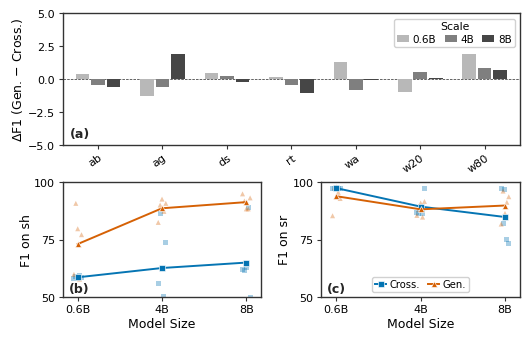

In [28]:
# ── Figure layout ────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(5.2, 3.3))

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    height_ratios=[1.15, 1.0],
    width_ratios=[1, 1],
    hspace=0.30,
    wspace=0.30,
)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])


# ── Shared styling ───────────────────────────────────────────────────────────
def style_axes(ax):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
        spine.set_color("0.20")

    ax.grid(False)

    ax.tick_params(
        axis="x",
        labelsize=8.0,
        length=3.0,
        width=0.8,
        color="0.20",
        pad=2.0,
    )

    ax.tick_params(
        axis="y",
        labelsize=8.0,
        length=3.0,
        width=0.8,
        color="0.20",
        pad=2.5,
    )


for ax in [ax_a, ax_b, ax_c]:
    style_axes(ax)


# ── (a) Delta grouped bars ───────────────────────────────────────────────────
x = np.arange(len(LEFT_DATASETS))

BAR_WIDTH = 0.24

SCALE_OFFSET = {
    "0.6b": -BAR_WIDTH,
    "4b": 0.0,
    "8b": BAR_WIDTH,
}

for scale in SCALES:
    values = (
        bar_data[bar_data["scale"] == scale]
        .set_index("dataset")
        .reindex(LEFT_DATASETS)["delta_f1"]
        .to_numpy()
    )

    ax_a.bar(
        x + SCALE_OFFSET[scale],
        values,
        width=BAR_WIDTH * 0.88,
        color=SCALE_COLOR[scale],
        edgecolor="none",
        label=SCALE_LABEL[scale],
        zorder=3,
    )

ax_a.axhline(
    0,
    color="0.15",
    linewidth=0.5,
    linestyle="--",
    zorder=2,
)

ax_a.set_xticks(x)
ax_a.set_xticklabels(
    LEFT_DATASETS,
    rotation=35,
    ha="right",
    rotation_mode="anchor",
    fontsize=8.0,
)

ax_a.set_xlim(-0.55, len(LEFT_DATASETS) - 0.45)
ax_a.set_ylim(-5, 5)
ax_a.set_yticks([-5, -2.5, 0, 2.5, 5])

ax_a.set_ylabel(
    r"$\Delta$F1 (Gen. $-$ Cross.)",
    fontsize=9.0,
    labelpad=2.0,
)

ax_a.text(
    0.015,
    0.04,
    "(a)",
    transform=ax_a.transAxes,
    ha="left",
    va="bottom",
    fontsize=9.0,
    fontweight="bold",
    color="0.15",
)

ax_a.legend(
    title="Scale",
    loc="upper right",
    ncol=3,
    fontsize=7.5,
    title_fontsize=7.8,
    frameon=True,
    framealpha=0.90,
    facecolor="white",
    edgecolor="0.80",
    borderpad=0.30,
    labelspacing=0.22,
    handlelength=1.15,
    handletextpad=0.35,
    columnspacing=0.80,
)


# ── Helper for panels (b) and (c) ────────────────────────────────────────────
def plot_scale_panel(ax, dataset, panel_label, add_legend=False):
    data_sub = right[right["dataset"] == dataset]
    mean_sub = mean_special[mean_special["dataset"] == dataset]

    x_scale = np.arange(len(SCALES))
    scale_to_x = dict(zip(SCALES, x_scale))

    for paradigm in PARADIGMS:
        dsub = data_sub[data_sub["paradigm"] == paradigm]

        # Individual seed points.
        for _, row in dsub.iterrows():
            ax.scatter(
                scale_to_x[row["scale"]] + seed_to_offset[row["seed"]],
                row["f1_pct"],
                s=13,
                color=COLOR[paradigm],
                marker=MARKER[paradigm],
                alpha=0.34,
                edgecolor="none",
                zorder=2,
            )

        # Mean curve.
        msub = (
            mean_sub[mean_sub["paradigm"] == paradigm]
            .set_index("scale")
            .reindex(SCALES)
        )

        ax.plot(
            x_scale,
            msub["f1_pct"].to_numpy(),
            color=COLOR[paradigm],
            marker=MARKER[paradigm],
            markersize=4.0,
            markeredgecolor="white",
            markeredgewidth=0.45,
            linewidth=1.4,
            alpha=0.98,
            label=LABEL[paradigm],
            zorder=4,
        )

    ax.set_xticks(x_scale)
    ax.set_xticklabels(
        [SCALE_LABEL[s] for s in SCALES],
        fontsize=8.0,
    )

    ax.set_xlim(-0.18, 2.18)
    ax.set_ylim(50, 100)
    ax.set_yticks([50, 75, 100])

    ax.set_xlabel(
        "Model Size",
        fontsize=9.0,
        labelpad=2.0,
    )

    ax.set_ylabel(
        f"F1 on {dataset}",
        fontsize=9.0,
        labelpad=1.0,
    )

    ax.text(
        0.03,
        0.015,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=9.0,
        fontweight="bold",
        color="0.15",
    )

    if add_legend:
        ax.legend(
            loc="lower center",
            ncol=2,
            fontsize=7.2,
            frameon=True,
            framealpha=0.90,
            facecolor="white",
            edgecolor="0.80",
            borderpad=0.28,
            labelspacing=0.20,
            handletextpad=0.35,
            handlelength=1.15,
            columnspacing=0.75,
        )


# ── (b) sh and (c) sr ────────────────────────────────────────────────────────
plot_scale_panel(
    ax_b,
    dataset="sh",
    panel_label="(b)",
    add_legend=False,
)

plot_scale_panel(
    ax_c,
    dataset="sr",
    panel_label="(c)",
    add_legend=True,
)

# ── Final spacing and save ───────────────────────────────────────────────────
fig.subplots_adjust(
    left=0.105,
    right=0.985,
    bottom=0.12,
    top=0.98,
)

fig.savefig(
    "figures/rq3_cross_gen_sh_sr.pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

# DATA ANATOMY

## SH -- Attribute Inconsistencies

In [29]:
from __future__ import annotations

import glob
import os
from collections import Counter

import ds_common as C

# =========================
# Configuration
# =========================

DATASET = "sh"
BALANCED_DATASET = "shb"

SCALES = C.SCALES

MAIN_CONFIGS = {
    "cross_encoder": "Base",
    "generative": "Base",
}

PRINT_CONFIGS = {
    "cross_encoder": "Base",
    "generative": "Base",
    "bi_encoder": "Embedding",
}

PARADIGM_DISPLAY = {
    "cross_encoder": "Cross-encoder",
    "generative": "Generative",
    "bi_encoder": "Bi-encoder",
}

UNSEEN_COMBOS = {
    ("amazonA", "bn_price"),
    ("amazonA", "amazonA"),
    ("other", "amazonA"),
    ("amazonA", "other"),
}

In [30]:
# =========================
# Helpers: schema-combo diagnostics
# =========================


def dialect(text: str) -> str:
    ks = set(k.lower() for k in C.attr_keys(text))

    if "pubyear" in ks or "pubmonth" in ks:
        return "catalog"
    if "price" in ks or "product dimensions" in ks or "shipping weight" in ks:
        return "amazonA"
    if "publication_date" in ks and "isbn13" in ks:
        return "bn_full"
    if "nook_book" in ks or "paperback" in ks or "sales_rank" in ks:
        return "bn_price"
    if "usedprice" in ks or "newprice" in ks:
        return "used"
    return "other"


def combo(A: dict, B: dict, r: dict) -> tuple[str, str]:
    return dialect(A[r["ltable_id"]]), dialect(B[r["rtable_id"]])


def unseen_mask(A: dict, B: dict, rows: list[dict]) -> tuple[np.ndarray, np.ndarray]:
    y = []
    unseen = []

    for r in rows:
        y.append(int(r["label"]))
        unseen.append(combo(A, B, r) in UNSEEN_COMBOS)

    return np.array(y), np.array(unseen)

In [31]:
# =========================
# Helpers: model metrics
# =========================


def classification_metrics(
    y: np.ndarray, pred: np.ndarray
) -> tuple[float, float, float]:
    y = np.asarray(y)
    pred = np.asarray(pred)

    tp = np.sum((y == 1) & (pred == 1))
    fp = np.sum((y == 0) & (pred == 1))
    fn = np.sum((y == 1) & (pred == 0))

    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")

    if np.isfinite(precision) and np.isfinite(recall) and (precision + recall) > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = float("nan")

    return f1, precision, recall


def seen_unseen_recall(
    y: np.ndarray,
    unseen: np.ndarray,
    pred: np.ndarray,
) -> tuple[float, float]:
    pos = y == 1
    unseen_pos = pos & unseen
    seen_pos = pos & ~unseen

    r_unseen = np.mean(pred[unseen_pos] == 1) if unseen_pos.sum() else float("nan")
    r_seen = np.mean(pred[seen_pos] == 1) if seen_pos.sum() else float("nan")

    return r_unseen, r_seen


def result_dirs(para: str, tag: str, dataset_name: str, scale: str) -> list[str]:
    if dataset_name == DATASET:
        base = os.path.join(C.RESULTS_ROOT, f"main_{scale}", para, dataset_name)
        pattern = os.path.join(base, f"*{tag}*seed*")

    elif dataset_name == BALANCED_DATASET:
        base = os.path.join(C.RESULTS_ROOT, "sh_rebalance_ablation", para, dataset_name)

        scale_tag = {
            "0.6b": "0.6B",
            "4b": "4B",
            "8b": "8B",
        }[scale]

        order = f"{tag}-{scale_tag}" if para == "bi_encoder" else f"{scale_tag}-{tag}"
        pattern = os.path.join(base, f"*{order}*seed*")

    else:
        raise ValueError(f"Unknown dataset: {dataset_name}")

    return sorted(glob.glob(pattern))


def collect_seed_metrics(
    para: str,
    tag: str,
    dataset_name: str,
    scale: str,
    y_ref: np.ndarray,
    unseen_ref: np.ndarray,
) -> list[dict]:
    rows = []

    for run in result_dirs(para, tag, dataset_name, scale):
        test_path = os.path.join(run, "test_results.json")
        log_path = os.path.join(run, "training_log.json")

        if not os.path.exists(test_path):
            continue

        with open(test_path) as f:
            preds_json = json.load(f)["predictions"]

        pred = np.array([p["pred"] for p in preds_json])
        plab = np.array([p["label"] for p in preds_json])

        if not np.array_equal(plab, y_ref):
            continue

        f1, precision, recall = classification_metrics(y_ref, pred)
        r_unseen, r_seen = seen_unseen_recall(y_ref, unseen_ref, pred)

        log_f1 = float("nan")
        if os.path.exists(log_path):
            with open(log_path) as f:
                log_f1 = json.load(f).get("test_f1", float("nan"))

        rows.append(
            {
                "run": run,
                "f1": f1,
                "precision": precision,
                "recall": recall,
                "log_f1": log_f1,
                "recall_unseen": r_unseen,
                "recall_seen": r_seen,
            }
        )

    return rows


def mean_std(values: list[float]) -> tuple[float, float]:
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return float("nan"), float("nan")

    mean = float(np.mean(values))
    std = float(np.std(values, ddof=1)) if len(values) > 1 else 0.0

    return mean, std


def metric_cell(rows: list[dict], key: str) -> str:
    values = np.array([r[key] for r in rows], dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return "NA"

    mean = values.mean() * 100
    std = values.std(ddof=1) * 100 if len(values) > 1 else 0.0

    return f"{mean:.1f} ± {std:.1f}"


def metric_mean(rows: list[dict], key: str) -> float:
    values = np.array([r[key] for r in rows], dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return float("nan")

    return float(values.mean() * 100)


# =========================
# Load data
# =========================

A_sh, B_sh, train_sh, valid_sh, test_sh = C.load_dataset(DATASET)
y_sh, unseen_sh = unseen_mask(A_sh, B_sh, test_sh)

A_hb, B_hb, train_hb, valid_hb, test_hb = C.load_dataset(BALANCED_DATASET)
y_hb, unseen_hb = unseen_mask(A_hb, B_hb, test_hb)

In [32]:
# =========================
# Output 1: positive schema-combo diagnostics
# =========================

print("=== positive schema-combo distribution ===")

for split_label, A, B, train, valid, test in (
    ("Original sh", A_sh, B_sh, train_sh, valid_sh, test_sh),
    ("Balanced shb", A_hb, B_hb, train_hb, valid_hb, test_hb),
):
    print(f"\n{split_label}:")
    for name, rows in (("train", train), ("valid", valid), ("test", test)):
        c = Counter(combo(A, B, r) for r in rows if int(r["label"]) == 1)
        n_pos = sum(c.values())
        n_unseen = sum(v for k, v in c.items() if k in UNSEEN_COMBOS)
        n_seen = n_pos - n_unseen

        unseen_rate = n_unseen / n_pos if n_pos else float("nan")

        print(
            f"  {name:6}: positives={n_pos:4d}  "
            f"unseen={n_unseen:4d}  seen={n_seen:4d}  "
            f"unseen_rate={unseen_rate:5.1%}  "
            f"top={dict(c.most_common(6))}"
        )

# Original sh: seen/unseen defined by train positive combos.
train_pos_combos = Counter(
    combo(A_sh, B_sh, r) for r in train_sh if int(r["label"]) == 1
)

test_combos = [combo(A_sh, B_sh, r) for r in test_sh]
seen_from_train = np.array([train_pos_combos.get(c, 0) > 0 for c in test_combos])

pos_sh = y_sh == 1
unseen_pos = np.where(pos_sh & ~seen_from_train)[0]
seen_pos = np.where(pos_sh & seen_from_train)[0]

print(
    f"\nOriginal sh test positives by train-observed combo: "
    f"seen={len(seen_pos)}, unseen={len(unseen_pos)} "
    f"({len(unseen_pos) / int(pos_sh.sum()):.0%} unseen)"
)

print("\n=== recall on train-seen vs train-unseen positive combos, original sh ===")
print(f"{'Model':15}{'Scale':7}{'n':>3}{'R(seen)':>14}{'R(unseen)':>14}{'Gap':>12}")
print("-" * 65)

for para, tag in MAIN_CONFIGS.items():
    for scale in SCALES:
        rows = collect_seed_metrics(
            para=para,
            tag=tag,
            dataset_name=DATASET,
            scale=scale,
            y_ref=y_sh,
            unseen_ref=~seen_from_train,
        )

        if not rows:
            continue

        r_seen = np.array([r["recall_seen"] for r in rows], dtype=float)
        r_unseen = np.array([r["recall_unseen"] for r in rows], dtype=float)
        gap = r_unseen - r_seen

        print(
            f"{PARADIGM_DISPLAY[para]:15}{scale:7}{len(rows):>3}"
            f"{metric_cell(rows, 'recall_seen'):>14}"
            f"{metric_cell(rows, 'recall_unseen'):>14}"
            f"{gap.mean() * 100:>8.1f} ± {gap.std(ddof=1) * 100 if len(gap) > 1 else 0.0:.1f}"
        )

    print()

=== positive schema-combo distribution ===

Original sh:
  train : positives= 474  unseen=   0  seen= 474  unseen_rate= 0.0%  top={('catalog', 'bn_full'): 154, ('amazonA', 'bn_full'): 150, ('other', 'other'): 92, ('catalog', 'other'): 77, ('other', 'bn_full'): 1}
  valid : positives= 157  unseen=   0  seen= 157  unseen_rate= 0.0%  top={('amazonA', 'bn_full'): 157}
  test  : positives= 159  unseen= 131  seen=  28  unseen_rate=82.4%  top={('amazonA', 'bn_price'): 99, ('amazonA', 'bn_full'): 20, ('amazonA', 'amazonA'): 18, ('other', 'amazonA'): 9, ('other', 'other'): 8, ('amazonA', 'other'): 5}

Balanced shb:
  train : positives= 473  unseen=  78  seen= 395  unseen_rate=16.5%  top={('amazonA', 'bn_full'): 196, ('catalog', 'bn_full'): 92, ('other', 'other'): 60, ('amazonA', 'bn_price'): 59, ('catalog', 'other'): 46, ('amazonA', 'amazonA'): 11}
  valid : positives= 160  unseen=  27  seen= 133  unseen_rate=16.9%  top={('amazonA', 'bn_full'): 66, ('catalog', 'bn_full'): 31, ('other', 'other')

In [33]:
# =========================
# Output 2: sh vs shb full-scale table with std
# =========================

print(
    f"\nsh  test: n={len(y_sh)}  unseen-combo positives="
    f"{int((unseen_sh & (y_sh == 1)).sum())}/{int((y_sh == 1).sum())}"
)

print(
    f"shb test: n={len(y_hb)}  unseen-combo positives="
    f"{int((unseen_hb & (y_hb == 1)).sum())}/{int((y_hb == 1).sum())}\n"
)

print("=== F1 / Precision / Recall / Recall by combo, all scales ===")
print(
    f"{'Model':15}{'Split':6}{'Scale':6}{'n':>3}"
    f"{'F1':>14}{'P':>14}{'R':>14}{'R(un)':>14}{'R(se)':>14}"
)
print("-" * 88)

for para, tag in PRINT_CONFIGS.items():
    for split_name, dataset_name, y_ref, unseen_ref in (
        ("sh", DATASET, y_sh, unseen_sh),
        ("shb", BALANCED_DATASET, y_hb, unseen_hb),
    ):
        for scale in SCALES:
            rows = collect_seed_metrics(
                para=para,
                tag=tag,
                dataset_name=dataset_name,
                scale=scale,
                y_ref=y_ref,
                unseen_ref=unseen_ref,
            )

            if not rows:
                continue

            print(
                f"{PARADIGM_DISPLAY[para]:15}{split_name:6}{scale:6}{len(rows):>3}"
                f"{metric_cell(rows, 'f1'):>14}"
                f"{metric_cell(rows, 'precision'):>14}"
                f"{metric_cell(rows, 'recall'):>14}"
                f"{metric_cell(rows, 'recall_unseen'):>14}"
                f"{metric_cell(rows, 'recall_seen'):>14}"
            )

    print()


sh  test: n=414  unseen-combo positives=131/159
shb test: n=410  unseen-combo positives=26/157

=== F1 / Precision / Recall / Recall by combo, all scales ===
Model          Split Scale   n            F1             P             R         R(un)         R(se)
----------------------------------------------------------------------------------------
Cross-encoder  sh    0.6b    5    58.7 ± 0.6    94.2 ± 1.1    42.6 ± 0.7    31.5 ± 0.6    95.0 ± 2.0
Cross-encoder  sh    4b      5   62.8 ± 16.9    94.0 ± 2.4   48.9 ± 19.9   40.0 ± 24.0    90.7 ± 6.5
Cross-encoder  sh    8b      5   65.1 ± 14.4    94.7 ± 1.9   51.1 ± 18.0   42.9 ± 22.1    89.3 ± 5.1
Cross-encoder  shb   0.6b    5    97.1 ± 0.5    97.1 ± 1.0    97.1 ± 1.2    94.6 ± 2.1    97.6 ± 1.0
Cross-encoder  shb   4b      5    97.3 ± 0.4    97.6 ± 0.8    97.1 ± 1.2    96.9 ± 3.2    97.1 ± 1.3
Cross-encoder  shb   8b      5    96.1 ± 2.5    96.0 ± 3.9    96.3 ± 1.8    93.1 ± 5.0    96.9 ± 1.8

Generative     sh    0.6b    5   73.2 ± 14.0

## SR - Class-conditional Feature Distribution Shift

In [34]:
from __future__ import annotations

import glob
import os

import ds_common as C

# =========================
# Configuration
# =========================

DATASET = "sr"
BALANCED_DATASET = "srb"

SCALES = C.SCALES

CONFIGS = {
    "cross_encoder": "Base",
    "generative": "Base",
}

PARADIGM_DISPLAY = {
    "cross_encoder": "Cross-encoder",
    "generative": "Generative",
}

B_TITLE_KEYS = ["Name", "movie_name", "Title", "title"]

# =========================
# Helpers: data diagnostics
# =========================


def get_field(text: str, keys: list[str]) -> str:
    fields = dict(zip(C.attr_keys(text), C.attr_values(text)))
    for k in keys:
        if k in fields:
            return fields[k].strip().lower()
    return ""


def title_collision(a_text: str, b_text: str) -> bool:
    ta = get_field(a_text, ["title"])
    tb = get_field(b_text, B_TITLE_KEYS)
    return bool(ta) and ta == tb


def collision_mask(A, B, rows):
    y = []
    coll = []

    for r in rows:
        y.append(int(r["label"]))

        a = A.get(r["ltable_id"], "")
        b = B.get(r["rtable_id"], "")

        coll.append(title_collision(a, b))

    return np.array(y), np.array(coll)


def collision_rate(rows, A, B, label_filter: int):
    n_coll = 0
    n_total = 0

    for r in rows:
        if int(r["label"]) != label_filter:
            continue

        a = A.get(r["ltable_id"], "")
        b = B.get(r["rtable_id"], "")

        n_total += 1
        if title_collision(a, b):
            n_coll += 1

    return n_coll, n_total

In [35]:
# =========================
# Helpers: model metrics
# =========================


def classification_metrics(y, pred):
    y = np.asarray(y)
    pred = np.asarray(pred)

    tp = np.sum((y == 1) & (pred == 1))
    fp = np.sum((y == 0) & (pred == 1))
    fn = np.sum((y == 1) & (pred == 0))

    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall = tp / (tp + fn) if (tp + fn) else float("nan")

    if np.isfinite(precision) and np.isfinite(recall) and precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = float("nan")

    return f1, precision, recall


def result_dirs(para: str, tag: str, dataset_name: str, scale: str):
    if dataset_name == DATASET:
        base = os.path.join(C.RESULTS_ROOT, f"main_{scale}", para, DATASET)
        pattern = os.path.join(base, f"*{tag}*seed*")

    elif dataset_name == BALANCED_DATASET:
        base = os.path.join(
            C.RESULTS_ROOT, "sr_rebalance_ablation", para, BALANCED_DATASET
        )

        scale_tag = {
            "0.6b": "0.6B",
            "4b": "4B",
            "8b": "8B",
        }[scale]

        # For cross/gen, directory names are usually "{scale}-{tag}".
        pattern = os.path.join(base, f"*{scale_tag}-{tag}*seed*")

    else:
        raise ValueError(f"Unknown dataset: {dataset_name}")

    return sorted(glob.glob(pattern))


def collect_seed_metrics(para, tag, dataset_name, scale, y_ref):
    rows = []

    for run in result_dirs(para, tag, dataset_name, scale):
        test_path = os.path.join(run, "test_results.json")

        if not os.path.exists(test_path):
            continue

        with open(test_path) as f:
            preds_json = json.load(f)["predictions"]

        plab = np.array([p["label"] for p in preds_json])

        if not np.array_equal(plab, y_ref):
            continue

        pred = np.array([p["pred"] for p in preds_json])

        f1, precision, recall = classification_metrics(y_ref, pred)

        rows.append(
            {
                "run": run,
                "f1": f1,
                "precision": precision,
                "recall": recall,
            }
        )

    return rows


def metric_cell(rows, key):
    vals = np.array([r[key] for r in rows], dtype=float)
    vals = vals[np.isfinite(vals)]

    if len(vals) == 0:
        return "NA"

    mean = vals.mean() * 100
    std = vals.std(ddof=1) * 100 if len(vals) > 1 else 0.0

    return f"{mean:.1f} ± {std:.1f}"


def metric_mean(rows, key):
    vals = np.array([r[key] for r in rows], dtype=float)
    vals = vals[np.isfinite(vals)]

    if len(vals) == 0:
        return np.nan

    return vals.mean() * 100


# =========================
# Load datasets
# =========================

A_sr, B_sr, train_sr, valid_sr, test_sr = C.load_dataset(DATASET)
y_sr, coll_sr = collision_mask(A_sr, B_sr, test_sr)

A_rb, B_rb, _, _, test_rb = C.load_dataset(BALANCED_DATASET)
y_rb, coll_rb = collision_mask(A_rb, B_rb, test_rb)

In [36]:
# =========================
# Output 1: title-collision diagnostics across partitions
# =========================

print("=== title-collision rate among NEGATIVES, by split ===")

for split_label, dataset_name in (
    ("Original sr", DATASET),
    ("Rebalanced srb", BALANCED_DATASET),
):
    A, B, train, valid, test = C.load_dataset(dataset_name)

    print(f"\n{split_label}:")
    for part_name, rows in (("train", train), ("valid", valid), ("test", test)):
        nc, nt = collision_rate(rows, A, B, label_filter=0)
        rate = nc / nt if nt else float("nan")
        print(f"  {part_name:6}: {nc:4d}/{nt:<4d} = {rate:5.1%}")

print(
    f"\nsr  test: n={len(y_sr)}  collision negatives="
    f"{int((coll_sr & (y_sr == 0)).sum())}/{int((y_sr == 0).sum())}"
)

print(
    f"srb test: n={len(y_rb)}  collision negatives="
    f"{int((coll_rb & (y_rb == 0)).sum())}/{int((y_rb == 0).sum())}"
)

=== title-collision rate among NEGATIVES, by split ===

Original sr:
  train :    4/764  =  0.5%
  valid :    1/256  =  0.4%
  test  :   73/254  = 28.7%

Rebalanced srb:
  train :   47/764  =  6.2%
  valid :   16/256  =  6.2%
  test  :   15/254  =  5.9%

sr  test: n=437  collision negatives=73/254
srb test: n=436  collision negatives=15/254


In [37]:
# =========================
# Output 2: plain full-scale table
# =========================

print("\n=== F1 / Precision / Recall, all scales ===")
print(f"{'Model':15}{'Split':6}{'Scale':6}{'n':>3}" f"{'F1':>12}{'P':>12}{'R':>12}")
print("-" * 66)

for para, tag in CONFIGS.items():
    for split_name, dataset_name, y_ref in (
        ("sr", DATASET, y_sr),
        ("srb", BALANCED_DATASET, y_rb),
    ):
        for scale in SCALES:
            rows = collect_seed_metrics(
                para=para,
                tag=tag,
                dataset_name=dataset_name,
                scale=scale,
                y_ref=y_ref,
            )

            if not rows:
                continue

            print(
                f"{PARADIGM_DISPLAY[para]:15}{split_name:6}{scale:6}{len(rows):>3}"
                f"{metric_cell(rows, 'f1'):>12}"
                f"{metric_cell(rows, 'precision'):>12}"
                f"{metric_cell(rows, 'recall'):>12}"
            )

    print()


=== F1 / Precision / Recall, all scales ===
Model          Split Scale   n          F1           P           R
------------------------------------------------------------------
Cross-encoder  sr    0.6b    5  97.6 ± 0.2  96.9 ± 0.9  98.3 ± 0.9
Cross-encoder  sr    4b      5  89.5 ± 4.7  81.7 ± 9.0  99.6 ± 1.0
Cross-encoder  sr    8b      5 85.0 ± 11.4 76.4 ± 19.0  98.7 ± 1.4
Cross-encoder  srb   0.6b    5  98.2 ± 0.4  97.7 ± 0.7  98.7 ± 1.1
Cross-encoder  srb   4b      5  98.3 ± 0.3  97.4 ± 0.4  99.2 ± 0.3
Cross-encoder  srb   8b      5  98.1 ± 0.7  97.4 ± 0.5  98.9 ± 1.0

Generative     sr    0.6b    5  94.0 ± 5.2 90.9 ± 10.1  98.0 ± 1.4
Generative     sr    4b      5  88.3 ± 3.1  80.7 ± 5.4  97.7 ± 0.5
Generative     sr    8b      5  90.0 ± 5.8 83.7 ± 10.5  98.0 ± 1.8
Generative     srb   0.6b    5  98.4 ± 0.3  97.6 ± 0.3  99.1 ± 0.7
Generative     srb   4b      5  98.3 ± 0.2  97.4 ± 0.4  99.2 ± 0.5
Generative     srb   8b      5  98.6 ± 0.3  98.4 ± 0.8  98.9 ± 0.5



# CROSS-DATASET TRANSFERABILITY OF FINE-TUNED MATCHERS

In [38]:
from __future__ import annotations
import csv, glob, json, os
from collections import defaultdict
import numpy as np
import ds_common as C

XD_ROOT = os.path.join(C.RESULTS_ROOT, "cross_dataset")
RAW = os.path.join("data", "rq1_raw_data.csv")
VARIANT = {"bi_encoder": "emb", "cross_encoder": "base", "generative": "base"}


def load_transfer():
    """(paradigm, src, tgt) -> dict of mean metrics over seeds."""
    acc = defaultdict(lambda: defaultdict(list))
    for f in glob.glob(os.path.join(XD_ROOT, "*", "*", "seed*.json")):
        d = json.load(open(f))
        key = (d["paradigm"], d["source"], d["target"])
        for m in (
            "test_f1",
            "test_f1_no_sweep",
            "test_auroc",
            "test_precision",
            "test_recall",
            "val_f1",
        ):
            v = d.get(m)
            if v is not None:
                acc[key][m].append(v)
    return {k: {m: float(np.mean(v)) for m, v in d.items()} for k, d in acc.items()}


def load_indomain():
    """(paradigm, ds) -> mean in-domain test F1 at 8b with the matching variant."""
    acc = defaultdict(list)
    for r in csv.DictReader(open(RAW)):
        if r["scale"] == "8b" and r["variant"] == VARIANT.get(r["paradigm"]):
            acc[(r["paradigm"], r["dataset"])].append(float(r["f1"]))
    return {k: float(np.mean(v)) for k, v in acc.items()}

In [39]:
T = load_transfer()
D = load_indomain()
order = C.ALIASES
long_rows = []

for para in C.PARADIGMS:
    print("=" * 100)
    print(f"### {para}  (rows = trained on, cols = evaluated on)")

    f1_mat = {}
    ret_mat = {}

    # Build matrices and long-format rows.
    for s in order:
        for t in order:
            if s == t:
                f1 = D.get((para, t), float("nan"))
                retention = 1.0 if not np.isnan(f1) else float("nan")

                # In-domain diagonal has no foreign-threshold or transfer-AUROC
                # interpretation, so these fields remain blank.
                long_rows.append(
                    {
                        "paradigm": para,
                        "source": s,
                        "target": t,
                        "test_f1": round(f1, 4) if not np.isnan(f1) else "",
                        "retention": (
                            round(retention, 4) if not np.isnan(retention) else ""
                        ),
                        "test_f1_no_sweep": "",
                        "test_auroc": "",
                    }
                )
            else:
                metrics = T.get((para, s, t), {})
                f1 = metrics.get("test_f1", float("nan"))
                indomain_f1 = D.get((para, t), float("nan"))

                retention = (
                    f1 / indomain_f1
                    if (
                        not np.isnan(f1)
                        and not np.isnan(indomain_f1)
                        and indomain_f1 != 0
                    )
                    else float("nan")
                )

                long_rows.append(
                    {
                        "paradigm": para,
                        "source": s,
                        "target": t,
                        "test_f1": round(f1, 4) if not np.isnan(f1) else "",
                        "retention": (
                            round(retention, 4) if not np.isnan(retention) else ""
                        ),
                        "test_f1_no_sweep": (
                            round(metrics["test_f1_no_sweep"], 4)
                            if "test_f1_no_sweep" in metrics
                            else ""
                        ),
                        "test_auroc": (
                            round(metrics["test_auroc"], 4)
                            if "test_auroc" in metrics
                            else ""
                        ),
                    }
                )

            f1_mat[(s, t)] = f1
            ret_mat[(s, t)] = retention

    # ------------------------------------------------------------------
    # 1. Raw F1 matrix
    # ------------------------------------------------------------------
    print("\nF1 matrix")
    print("rows = trained on, cols = evaluated on; diagonal = in-domain")
    hdr = (
        "{:<8}".format("src\\tgt")
        + "".join(f"{t:>8}" for t in order)
        + f"{'out_avg':>9}"
    )
    print(hdr)

    for s in order:
        cells = [f1_mat[(s, t)] for t in order]
        outgoing_f1 = [
            f1_mat[(s, t)] for t in order if t != s and not np.isnan(f1_mat[(s, t)])
        ]
        out_avg = float(np.mean(outgoing_f1)) if outgoing_f1 else float("nan")

        print(
            f"{s:<8}"
            + "".join(f"{v:>8.3f}" if not np.isnan(v) else f"{'-':>8}" for v in cells)
            + (f"{out_avg:>9.3f}" if not np.isnan(out_avg) else f"{'-':>9}")
        )

    incoming_f1 = []
    for t in order:
        values = [
            f1_mat[(s, t)] for s in order if s != t and not np.isnan(f1_mat[(s, t)])
        ]
        incoming_f1.append(float(np.mean(values)) if values else float("nan"))

    print(
        f"{'in_avg':<8}"
        + "".join(f"{v:>8.3f}" if not np.isnan(v) else f"{'-':>8}" for v in incoming_f1)
    )

    # ------------------------------------------------------------------
    # 2. Retention matrix
    # ------------------------------------------------------------------
    print("\nRetention matrix")
    print("retention = transfer F1 / target in-domain F1; diagonal = 1.0")
    print(hdr)

    for s in order:
        cells = [ret_mat[(s, t)] for t in order]
        outgoing_retention = [
            ret_mat[(s, t)] for t in order if t != s and not np.isnan(ret_mat[(s, t)])
        ]
        out_avg = (
            float(np.mean(outgoing_retention)) if outgoing_retention else float("nan")
        )

        print(
            f"{s:<8}"
            + "".join(f"{v:>8.3f}" if not np.isnan(v) else f"{'-':>8}" for v in cells)
            + (f"{out_avg:>9.3f}" if not np.isnan(out_avg) else f"{'-':>9}")
        )

    incoming_retention = []
    for t in order:
        values = [
            ret_mat[(s, t)] for s in order if s != t and not np.isnan(ret_mat[(s, t)])
        ]
        incoming_retention.append(float(np.mean(values)) if values else float("nan"))

    print(
        f"{'in_avg':<8}"
        + "".join(
            f"{v:>8.3f}" if not np.isnan(v) else f"{'-':>8}" for v in incoming_retention
        )
    )

    # ------------------------------------------------------------------
    # Paradigm-level summary
    # ------------------------------------------------------------------
    offdiag_f1 = [
        f1_mat[(s, t)]
        for s in order
        for t in order
        if s != t and not np.isnan(f1_mat[(s, t)])
    ]
    offdiag_retention = [
        ret_mat[(s, t)]
        for s in order
        for t in order
        if s != t and not np.isnan(ret_mat[(s, t)])
    ]

    print(
        "\nsummary: "
        f"mean off-diag F1 = {np.mean(offdiag_f1):.3f}   "
        f"mean retention = {np.mean(offdiag_retention):.3f}   "
        f"median retention = {np.median(offdiag_retention):.3f}"
    )
    print()

### bi_encoder  (rows = trained on, cols = evaluated on)

F1 matrix
rows = trained on, cols = evaluated on; diagonal = in-domain
src\tgt       ab      ag      ds      rt      sh      sr      wa     w20     w80  out_avg
ab         0.911   0.200   0.314   0.301   0.525   0.595   0.207   0.199   0.200    0.318
ag         0.196   0.763   0.322   0.299   0.526   0.591   0.197   0.199   0.200    0.316
ds         0.198   0.203   0.953   0.301   0.526   0.595   0.175   0.197   0.200    0.300
rt         0.196   0.184   0.311   0.720   0.540   0.591   0.169   0.196   0.198    0.298
sh         0.196   0.191   0.323   0.301   0.860   0.595   0.166   0.197   0.200    0.271
sr         0.195   0.184   0.316   0.302   0.530   0.856   0.168   0.200   0.198    0.262
wa         0.206   0.212   0.320   0.300   0.516   0.592   0.819   0.199   0.201    0.318
w20        0.242   0.225   0.306   0.301   0.535   0.589   0.222   0.762   0.199    0.327
w80        0.210   0.200   0.319   0.298   0.520   0.591   0.

In [40]:
# protocol decomposition for cross & bi
print("=" * 100)
print("### protocol decomposition (off-diagonal means): ranking vs operating point")
print(f"{'paradigm':15}{'AUROC':>8}{'F1@tgt-val-thr':>16}{'F1@src-thr':>12}")
for para in ["cross_encoder", "bi_encoder"]:
    au, fv, fn = [], [], []
    for (p, s, t), d in T.items():
        if p != para or s == t:
            continue
        if "test_auroc" in d:
            au.append(d["test_auroc"])
        fv.append(d["test_f1"])
        if "test_f1_no_sweep" in d:
            fn.append(d["test_f1_no_sweep"])
    print(f"{para:15}{np.mean(au):>8.3f}{np.mean(fv):>16.3f}{np.mean(fn):>12.3f}")

out = os.path.join(C.OUT_DIR, "cross_dataset_matrix.csv")
with open(out, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(long_rows[0]))
    w.writeheader()
    w.writerows(long_rows)
print(f"\n[written] {out}")

### protocol decomposition (off-diagonal means): ranking vs operating point
paradigm          AUROC  F1@tgt-val-thr  F1@src-thr
cross_encoder     0.867           0.649       0.534
bi_encoder        0.555           0.303       0.141

[written] data/cross_dataset_matrix.csv


In [41]:
import matplotlib as mpl

mpl.rcdefaults()

import os

# =========================
# Configuration
# =========================

CSV_PATH = "data/cross_dataset_matrix.csv"
OUTPUT_PATH = "figures/cross_dataset_retention.pdf"

DATASET_ORDER = [
    "ab",
    "ag",
    "ds",
    "rt",
    "sh",
    "sr",
    "wa",
    "w20",
    "w80",
]

PARADIGM_ORDER = [
    "bi_encoder",
    "cross_encoder",
    "generative",
]

PARADIGM_DISPLAY = {
    "bi_encoder": "Bi-encoder",
    "cross_encoder": "Cross-encoder",
    "generative": "Generative",
}

SHORT_DISPLAY = {
    "bi_encoder": "Bi.",
    "cross_encoder": "Cross.",
    "generative": "Gen.",
}

# Heatmap scale
VMIN = 0
VCENTER = 50
VMAX = 100
CMAP = "RdBu_r"

# Figure size
FIG_W = 7.10
FIG_H = 2.35

# Fonts
PANEL_FS = 7.2
TITLE_FS = 6.6
TICK_FS = 5.3
CELL_FS = 4.6
DIST_LABEL_FS = 5.8
CBAR_LABEL_FS = 5.8
CBAR_TICK_FS = 5.3

TEXT_WHITE_THRESHOLD = 75

In [42]:
# =========================
# Load data
# =========================

df = pd.read_csv(CSV_PATH)

required_cols = {
    "paradigm",
    "source",
    "target",
    "test_f1",
    "retention",
    "test_f1_no_sweep",
    "test_auroc",
}

missing = required_cols - set(df.columns)

if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

df = df.copy()

# Convert retention to percentage if stored in [0, 1].
if df["retention"].max() <= 1.5:
    df["retention_pct"] = df["retention"] * 100
else:
    df["retention_pct"] = df["retention"]

# Convert F1 to percentage if stored in [0, 1].
if df["test_f1"].max() <= 1.5:
    df["test_f1_pct"] = df["test_f1"] * 100
else:
    df["test_f1_pct"] = df["test_f1"]

# Keep only requested paradigms and datasets.
df = df[
    df["paradigm"].isin(PARADIGM_ORDER)
    & df["source"].isin(DATASET_ORDER)
    & df["target"].isin(DATASET_ORDER)
].copy()

# Off-diagonal source-target pairs only.
off = df[df["source"] != df["target"]].copy()

if off.empty:
    raise ValueError("No off-diagonal rows remain after filtering.")

# Explicit check that panel (a) uses no diagonal entries.
assert not (off["source"] == off["target"]).any()

In [43]:
# =========================
# Helpers
# =========================


def build_retention_matrix(
    data: pd.DataFrame,
    paradigm: str,
    dataset_order: list[str],
):
    """
    Build an augmented retention matrix.

    The final column contains outgoing averages.
    The final row contains incoming averages.
    The bottom-right cell contains the global off-diagonal average.
    """
    sub = data[data["paradigm"] == paradigm].copy()

    mat = sub.pivot_table(
        index="source",
        columns="target",
        values="retention_pct",
        aggfunc="mean",
    ).reindex(
        index=dataset_order,
        columns=dataset_order,
    )

    arr = mat.to_numpy(dtype=float)
    n = len(dataset_order)

    off_diag_mask = ~np.eye(
        n,
        dtype=bool,
    )

    out_avg = np.full(
        n,
        np.nan,
    )

    in_avg = np.full(
        n,
        np.nan,
    )

    for i in range(n):
        row_values = arr[
            i,
            off_diag_mask[i],
        ]

        if np.any(np.isfinite(row_values)):
            out_avg[i] = np.nanmean(row_values)

    for j in range(n):
        col_values = arr[
            off_diag_mask[:, j],
            j,
        ]

        if np.any(np.isfinite(col_values)):
            in_avg[j] = np.nanmean(col_values)

    off_diag_values = arr[off_diag_mask]

    if np.any(np.isfinite(off_diag_values)):
        global_off_avg = np.nanmean(off_diag_values)
    else:
        global_off_avg = np.nan

    full = np.full(
        (n + 1, n + 1),
        np.nan,
    )

    full[:n, :n] = arr
    full[:n, n] = out_avg
    full[n, :n] = in_avg
    full[n, n] = global_off_avg

    row_labels = dataset_order + ["IN"]
    col_labels = dataset_order + ["OUT"]

    return full, row_labels, col_labels


def draw_distribution(
    ax: plt.Axes,
    data: pd.DataFrame,
    value_column: str,
    ylabel: str,
    ylim_mode: str,
):
    """
    Draw a compact violin plot with an overlaid boxplot.
    """
    positions = np.arange(len(PARADIGM_ORDER))

    plot_data = []

    for paradigm in PARADIGM_ORDER:
        values = (
            data.loc[
                data["paradigm"] == paradigm,
                value_column,
            ]
            .dropna()
            .to_numpy(dtype=float)
        )

        if values.size == 0:
            raise ValueError(
                f"No valid values for {value_column!r}, " f"paradigm={paradigm!r}."
            )

        plot_data.append(values)

    # Violin envelope
    violin = ax.violinplot(
        plot_data,
        positions=positions,
        widths=0.72,
        showmeans=False,
        showmedians=False,
        showextrema=False,
        points=100,
    )

    for body in violin["bodies"]:
        body.set_facecolor("0.88")
        body.set_edgecolor("0.55")
        body.set_linewidth(0.45)
        body.set_alpha(1.0)

    # Boxplot overlay
    boxplot = ax.boxplot(
        plot_data,
        positions=positions,
        widths=0.28,
        patch_artist=True,
        showfliers=False,
        whis=(5, 95),
        medianprops={
            "color": "0.05",
            "linewidth": 1.0,
        },
        boxprops={
            "linewidth": 0.65,
            "edgecolor": "0.20",
        },
        whiskerprops={
            "linewidth": 0.55,
            "color": "0.30",
        },
        capprops={
            "linewidth": 0.55,
            "color": "0.30",
        },
    )

    for patch in boxplot["boxes"]:
        patch.set_facecolor("white")
        patch.set_alpha(0.90)

    ax.set_xticks(positions)

    ax.set_xticklabels(
        [SHORT_DISPLAY[p] for p in PARADIGM_ORDER],
        fontsize=TICK_FS,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=DIST_LABEL_FS,
        labelpad=1.5,
    )

    all_values = data[value_column].dropna().to_numpy(dtype=float)

    if ylim_mode == "fixed_100":
        # F1 always uses the complete percentage range.
        ax.set_ylim(0, 100)
        ax.set_yticks(np.arange(0, 101, 20))

    elif ylim_mode == "adaptive":
        # Retention uses the original adaptive range.
        y_low = max(
            0,
            np.floor((np.min(all_values) - 5) / 10) * 10,
        )

        y_high = np.ceil((np.max(all_values) + 5) / 10) * 10

        ax.set_ylim(
            y_low,
            y_high,
        )

    else:
        raise ValueError(f"Unknown ylim_mode: {ylim_mode!r}")

    # No horizontal grid because the two panels use
    # different y-axis ranges.
    ax.grid(False)

    ax.tick_params(
        axis="y",
        labelsize=TICK_FS,
        length=1.8,
        width=0.5,
        pad=1.0,
    )

    ax.tick_params(
        axis="x",
        length=0,
        pad=1.5,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    for side in ["left", "bottom"]:
        ax.spines[side].set_linewidth(0.55)
        ax.spines[side].set_color("0.35")

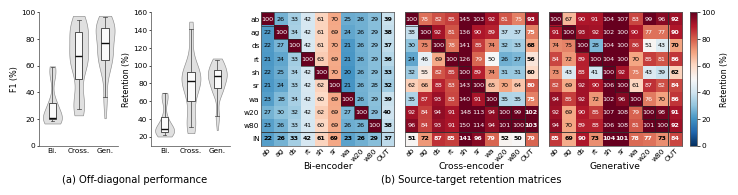

In [44]:
# =========================
# Figure layout
# =========================

norm = TwoSlopeNorm(
    vmin=VMIN,
    vcenter=VCENTER,
    vmax=VMAX,
)

fig = plt.figure(figsize=(FIG_W, FIG_H))

outer = fig.add_gridspec(
    nrows=1,
    ncols=2,
    # Panel (a) receives more horizontal space.
    width_ratios=[1.75, 3.85],
    wspace=0.10,
)

# Panel (a): F1 and retention arranged horizontally.
dist_gs = outer[0, 0].subgridspec(
    nrows=1,
    ncols=2,
    # Slightly larger gap between the two violin plots.
    wspace=0.42,
)

ax_f1 = fig.add_subplot(dist_gs[0, 0])

ax_retention = fig.add_subplot(dist_gs[0, 1])

dist_axes = [
    ax_f1,
    ax_retention,
]

# Panel (b): three heatmaps.
heat_gs = outer[0, 1].subgridspec(
    nrows=1,
    ncols=3,
    wspace=0.08,
)

heat_axes = [fig.add_subplot(heat_gs[0, i]) for i in range(3)]

# =========================
# Panel (a): distributions
# =========================

draw_distribution(
    ax=ax_f1,
    data=off,
    value_column="test_f1_pct",
    ylabel="F1 (%)",
    ylim_mode="fixed_100",
)

draw_distribution(
    ax=ax_retention,
    data=off,
    value_column="retention_pct",
    ylabel="Retention (%)",
    ylim_mode="adaptive",
)


# =========================
# Panel (b): heatmaps
# =========================

im = None

for ax, paradigm in zip(
    heat_axes,
    PARADIGM_ORDER,
):
    mat, row_labels, col_labels = build_retention_matrix(
        df,
        paradigm,
        DATASET_ORDER,
    )

    im = ax.imshow(
        mat,
        aspect="equal",
        cmap=CMAP,
        norm=norm,
        interpolation="nearest",
    )

    ax.set_xticks(np.arange(len(col_labels)))

    ax.set_xticklabels(
        col_labels,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
        fontsize=TICK_FS,
    )

    ax.set_yticks(np.arange(len(row_labels)))

    if ax is heat_axes[0]:
        ax.set_yticklabels(
            row_labels,
            fontsize=TICK_FS,
        )
    else:
        ax.tick_params(
            axis="y",
            labelleft=False,
        )

    n = len(DATASET_ORDER)

    # Separate aggregate row and column.
    ax.axhline(
        n - 0.5,
        color="0.20",
        linewidth=0.65,
    )

    ax.axvline(
        n - 0.5,
        color="0.20",
        linewidth=0.65,
    )

    # Outline diagonal cells.
    for i in range(n):
        ax.add_patch(
            plt.Rectangle(
                (i - 0.5, i - 0.5),
                1,
                1,
                fill=False,
                edgecolor="0.15",
                linewidth=0.45,
            )
        )

    # Cell annotations.
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            value = mat[i, j]

            if not np.isfinite(value):
                label = "NA"
                text_color = "black"
            else:
                label = f"{value:.0f}"

                text_color = "white" if value >= TEXT_WHITE_THRESHOLD else "black"

            is_average = i == n or j == n

            ax.text(
                j,
                i,
                label,
                ha="center",
                va="center",
                fontsize=CELL_FS,
                fontweight=("bold" if is_average else "normal"),
                color=text_color,
            )

    ax.tick_params(
        axis="both",
        length=0,
        pad=1.0,
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.55)
        spine.set_color("0.35")

# =========================
# Initial spacing
# =========================

fig.subplots_adjust(
    left=0.050,
    right=0.955,
    bottom=0.245,
    top=0.945,
)

fig.canvas.draw()

# =========================
# Align panel (a) with heatmap body
# =========================

heat_pos = heat_axes[0].get_position()

for ax in dist_axes:
    pos = ax.get_position()

    ax.set_position(
        [
            pos.x0,
            heat_pos.y0,
            pos.width,
            heat_pos.height,
        ]
    )

fig.canvas.draw()


# =========================
# Bottom labels
# =========================

f1_pos = ax_f1.get_position()
retention_pos = ax_retention.get_position()

first_heat_pos = heat_axes[0].get_position()
last_heat_pos = heat_axes[-1].get_position()

dist_left = f1_pos.x0
dist_right = retention_pos.x1

dist_bottom = min(
    f1_pos.y0,
    retention_pos.y0,
)

panel_title_y = (
    min(
        dist_bottom,
        first_heat_pos.y0,
    )
    - 0.125
)

paradigm_y = first_heat_pos.y0 - 0.070

fig.text(
    (dist_left + dist_right) / 2,
    panel_title_y,
    "(a) Off-diagonal performance",
    ha="center",
    va="top",
    fontsize=PANEL_FS,
)

for ax, paradigm in zip(
    heat_axes,
    PARADIGM_ORDER,
):
    pos = ax.get_position()

    fig.text(
        pos.x0 + pos.width / 2,
        paradigm_y,
        PARADIGM_DISPLAY[paradigm],
        ha="center",
        va="top",
        fontsize=TITLE_FS,
    )

fig.text(
    (first_heat_pos.x0 + last_heat_pos.x1) / 2,
    panel_title_y,
    "(b) Source-target retention matrices",
    ha="center",
    va="top",
    fontsize=PANEL_FS,
)


# =========================
# Manual colorbar
# =========================

fig.canvas.draw()

ref_pos = heat_axes[-1].get_position()

cbar_pad = 0.012
cbar_width = 0.010

cax = fig.add_axes(
    [
        ref_pos.x1 + cbar_pad,
        ref_pos.y0,
        cbar_width,
        ref_pos.height,
    ]
)

cbar = fig.colorbar(
    im,
    cax=cax,
)

cbar.set_label(
    "Retention (%)",
    fontsize=CBAR_LABEL_FS,
    labelpad=3,
)

cbar.ax.tick_params(
    labelsize=CBAR_TICK_FS,
    length=2.0,
    width=0.5,
    pad=1.0,
)

cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.0f"))

cbar.outline.set_linewidth(0.55)
cbar.outline.set_edgecolor("0.35")

# =========================
# Save
# =========================

output_dir = os.path.dirname(OUTPUT_PATH)

if output_dir:
    os.makedirs(
        output_dir,
        exist_ok=True,
    )

fig.savefig(
    OUTPUT_PATH,
    bbox_inches="tight",
    pad_inches=0.01,
)

plt.show()

# COST ANALYSIS

## inference-f1 frontier

In [45]:
import csv
import json
import statistics
from pathlib import Path

EFF_DIR = Path("../results/inference_efficiency")
OUT_PATH = Path("data/cost_summary.csv")

DATASETS = ["ab", "ag", "ds", "rt", "sh", "sr", "w20", "w80", "wa"]
SCALES = ["0.6b", "4b", "8b"]
# RoBERTa-base backbone used by both non-Qwen baselines.
BASELINE_SCALE = "125m"

# paradigm -> (variant in rq2_raw_data.csv, folder name under results/inference_efficiency)
TUNED_PARADIGMS = {
    "bi_encoder": "emb",
    "cross_encoder": "base",
    "generative": "base",
}


def load_f1_main():
    rows = list(csv.DictReader(open("data/rq2_raw_data.csv")))
    f1 = {}
    for paradigm, variant in TUNED_PARADIGMS.items():
        for scale in SCALES:
            for dataset in DATASETS:
                vals = [
                    float(r["f1"])
                    for r in rows
                    if r["paradigm"] == paradigm
                    and r["variant"] == variant
                    and r["scale"] == scale
                    and r["dataset"] == dataset
                ]
                if vals:
                    f1[(paradigm, scale, dataset)] = statistics.mean(vals)
    return f1


def load_f1_baselines():
    rows = list(csv.DictReader(open("data/rq2_baselines_raw_data.csv")))
    f1 = {}
    for method in ["sbert", "ditto"]:
        for dataset in DATASETS:
            vals = [
                float(r["f1"])
                for r in rows
                if r["method"] == method and r["dataset"] == dataset
            ]
            if vals:
                f1[(method, dataset)] = statistics.mean(vals)
    return f1

In [46]:
f1_main = load_f1_main()
f1_baselines = load_f1_baselines()

out_rows = []

for method in ["sbert", "ditto"]:
    for dataset in DATASETS:
        path = EFF_DIR / "baselines" / method / f"{dataset}.json"
        data = json.loads(path.read_text())
        f1 = f1_baselines.get((method, dataset), "")
        out_rows.append(
            {
                "dataset": dataset,
                "paradigm": method,
                "scale": BASELINE_SCALE,
                "throughput": round(data["effective_throughput_pairs_per_s"], 2),
                "F1": round(f1, 4) if f1 != "" else "",
                "peak_gpu_memory_mb": round(data["peak_gpu_memory_mb"], 2),
            }
        )

for paradigm in TUNED_PARADIGMS:
    for scale in SCALES:
        for dataset in DATASETS:
            path = EFF_DIR / paradigm / scale / f"{dataset}.json"
            data = json.loads(path.read_text())
            f1 = f1_main.get((paradigm, scale, dataset), "")
            out_rows.append(
                {
                    "dataset": dataset,
                    "paradigm": paradigm,
                    "scale": scale,
                    "throughput": round(data["effective_throughput_pairs_per_s"], 2),
                    "F1": round(f1, 4) if f1 != "" else "",
                    "peak_gpu_memory_mb": round(data["peak_gpu_memory_mb"], 2),
                }
            )

with open(OUT_PATH, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "dataset",
            "paradigm",
            "scale",
            "throughput",
            "F1",
            "peak_gpu_memory_mb",
        ],
    )
    writer.writeheader()
    writer.writerows(out_rows)

print(f"Wrote {len(out_rows)} rows to {OUT_PATH}")

Wrote 99 rows to data/cost_summary.csv


In [47]:
import matplotlib as mpl

mpl.rcdefaults()

from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, NullFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# =========================
# Configuration
# =========================

CSV_PATH = "data/cost_summary.csv"

ALL_DATASETS = ["ab", "ag", "ds", "rt", "sh", "sr", "w20", "w80", "wa"]

SHSR = ["sh", "sr"]
CLEAN7 = [d for d in ALL_DATASETS if d not in SHSR]

PANELS = [
    ("All datasets", ALL_DATASETS),
    ("All except sh, sr", CLEAN7),
    ("sh + sr", SHSR),
]

PARADIGM_ORDER = [
    "bi_encoder",
    "cross_encoder",
    "generative",
]

PARADIGM_LABEL = {
    "bi_encoder": "Bi.",
    "cross_encoder": "Cross.",
    "generative": "Gen.",
}

COLOR = {
    "bi_encoder": "#1f77b4",
    "cross_encoder": "#ff7f0e",
    "generative": "#d62728",
}

# Drawing order: slow/large -> fast/small
SCALES = ["8b", "4b", "0.6b"]

SCALE_LABEL = {
    "8b": "8B",
    "4b": "4B",
    "0.6b": "0.6B",
}

# Marker area encodes model scale.
# The differences are intentionally restrained.
SCALE_SIZE = {
    "8b": 30,
    "4b": 23,
    "0.6b": 17,
}

BASELINE_MARKER = {
    "sbert": "D",
    "ditto": "s",
}

BASELINE_LABEL = {
    "sbert": "SBERT",
    "ditto": "Ditto",
}

# VLDB-style single-column figure.
FIG_W = 3.45
FIG_H = 1.42

LINE_WIDTH = 0.80
POINT_EDGE_WIDTH = 0.38
BASELINE_SIZE = 22

TITLE_FS = 6.5
AXIS_LABEL_FS = 6.2
TICK_FS = 5.5
LEGEND_FS = 5.0
PANEL_FS = 6.4

In [48]:
# =========================
# Load and normalize data
# =========================

df = pd.read_csv(CSV_PATH)

required_cols = {
    "dataset",
    "paradigm",
    "scale",
    "throughput",
    "F1",
}

missing = required_cols - set(df.columns)

if missing:
    raise ValueError(
        f"Missing required columns: {sorted(missing)}\n"
        f"Available columns: {sorted(df.columns)}"
    )

df = df.copy()

for col in ["dataset", "paradigm", "scale"]:
    df[col] = df[col].astype(str).str.strip().str.lower()

df["throughput"] = pd.to_numeric(
    df["throughput"],
    errors="coerce",
)

df["F1"] = pd.to_numeric(
    df["F1"],
    errors="coerce",
)

df = df.dropna(
    subset=[
        "dataset",
        "paradigm",
        "scale",
        "throughput",
        "F1",
    ]
).copy()

# Support F1 represented either as [0, 1] or [0, 100].
if df["F1"].max() <= 1.5:
    df["f1_pct"] = df["F1"] * 100
else:
    df["f1_pct"] = df["F1"]

In [49]:
# =========================
# Helpers
# =========================


def aggregate(data, datasets):
    """
    Average throughput and F1 over the selected datasets.
    """
    sub = data[data["dataset"].isin(datasets)].copy()

    return sub.groupby(
        ["paradigm", "scale"],
        as_index=False,
    ).agg(
        throughput=("throughput", "mean"),
        f1_pct=("f1_pct", "mean"),
    )


def style_axes(ax):
    ax.set_facecolor("white")
    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.50)
        spine.set_color("0.55")

    ax.tick_params(
        axis="both",
        which="major",
        length=1.8,
        width=0.45,
        labelsize=TICK_FS,
        pad=1.2,
        color="0.30",
    )

    ax.tick_params(
        axis="both",
        which="minor",
        length=0,
    )

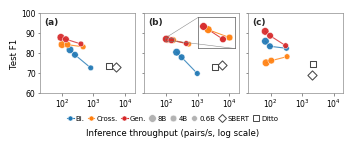

In [50]:
# =========================
# Main figure
# =========================

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(FIG_W, FIG_H),
    sharex=True,
    sharey=True,
)

panel_labels = ["(a)", "(b)", "(c)"]

scale_rank = {scale: idx for idx, scale in enumerate(SCALES)}

for panel_idx, (ax, (title, datasets)) in enumerate(zip(axes, PANELS)):
    style_axes(ax)

    agg = aggregate(df, datasets)

    # Panel label in the upper-left corner.
    ax.text(
        0.045,
        0.95,
        panel_labels[panel_idx],
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=PANEL_FS,
        fontweight="bold",
        color="0.15",
        zorder=10,
    )

    # -------------------------
    # LLM paradigms
    # -------------------------

    for paradigm in PARADIGM_ORDER:
        sub = agg[agg["paradigm"] == paradigm].copy()

        if sub.empty:
            continue

        sub["scale_rank"] = sub["scale"].map(scale_rank)
        sub = sub.dropna(subset=["scale_rank"])
        sub = sub.sort_values("scale_rank")

        if sub.empty:
            continue

        xs = sub["throughput"].to_numpy()
        ys = sub["f1_pct"].to_numpy()
        scales = sub["scale"].tolist()

        ax.plot(
            xs,
            ys,
            color=COLOR[paradigm],
            linewidth=LINE_WIDTH,
            alpha=0.80,
            zorder=2,
        )

        ax.scatter(
            xs,
            ys,
            s=[SCALE_SIZE.get(scale, 20) for scale in scales],
            color=COLOR[paradigm],
            edgecolor="white",
            linewidth=POINT_EDGE_WIDTH,
            alpha=0.92,
            zorder=3,
        )

    # -------------------------
    # Baselines
    # -------------------------

    for method, marker in BASELINE_MARKER.items():
        sub = agg[(agg["paradigm"] == method) & (agg["scale"] == "125m")]

        if sub.empty:
            continue

        x = sub.iloc[0]["throughput"]
        y = sub.iloc[0]["f1_pct"]

        ax.scatter(
            [x],
            [y],
            s=BASELINE_SIZE,
            facecolor="white",
            edgecolor="0.28",
            linewidth=0.75,
            marker=marker,
            zorder=4,
        )

    ax.set_xscale("log")
    ax.set_xlim(20, 2e4)

    ax.xaxis.set_major_locator(
        LogLocator(
            base=10,
            numticks=4,
        )
    )

    ax.xaxis.set_minor_formatter(NullFormatter())



# =========================
# Zoom inset in panel (b)
# Cross / Generative, 4B / 8B only
# =========================

ax_main = axes[1]

zoom_paradigms = [
    "cross_encoder",
    "generative",
]

zoom_scales = [
    "8b",
    "4b",
]

zoom_agg = aggregate(df, CLEAN7)

zoom_sub = zoom_agg[
    zoom_agg["paradigm"].isin(zoom_paradigms) & zoom_agg["scale"].isin(zoom_scales)
].copy()

if not zoom_sub.empty:

    # Compact inset in the upper-right corner.
    ax_zoom = inset_axes(
        ax_main,
        width="38%",
        height="39%",
        loc="upper right",
        borderpad=0.32,
    )

    inset_scale_rank = {
        "8b": 0,
        "4b": 1,
    }

    for paradigm in zoom_paradigms:
        sub = zoom_sub[zoom_sub["paradigm"] == paradigm].copy()

        if sub.empty:
            continue

        sub["scale_rank"] = sub["scale"].map(inset_scale_rank)

        sub = sub.sort_values("scale_rank")

        xs = sub["throughput"].to_numpy()
        ys = sub["f1_pct"].to_numpy()
        scales = sub["scale"].tolist()

        ax_zoom.plot(
            xs,
            ys,
            color=COLOR[paradigm],
            linewidth=0.72,
            alpha=0.88,
            zorder=2,
        )

        ax_zoom.scatter(
            xs,
            ys,
            s=[SCALE_SIZE[scale] for scale in scales],
            color=COLOR[paradigm],
            edgecolor="white",
            linewidth=0.32,
            alpha=0.96,
            zorder=3,
        )

    # Compute tight limits from only these four points.
    x_values = zoom_sub["throughput"].to_numpy()
    y_values = zoom_sub["f1_pct"].to_numpy()

    x_min = x_values.min()
    x_max = x_values.max()
    y_min = y_values.min()
    y_max = y_values.max()

    # Multiplicative padding for the logarithmic x-axis.
    x_padding = 1.10

    # Tight but non-degenerate vertical range.
    y_range = y_max - y_min
    y_padding = max(0.08, y_range * 0.18)

    ax_zoom.set_xscale("log")

    ax_zoom.set_xlim(
        x_min / x_padding,
        x_max * x_padding,
    )

    ax_zoom.set_ylim(
        y_min - 4 * y_padding,
        y_max + 4 * y_padding,
    )

    # No grid lines.
    ax_zoom.grid(False)
    ax_zoom.set_facecolor("white")

    for spine in ax_zoom.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.48)
        spine.set_color("0.32")

    # No text, labels, or tick marks inside the zoomed panel.
    ax_zoom.set_xticks([])
    ax_zoom.set_yticks([])

    ax_zoom.tick_params(
        axis="both",
        which="both",
        bottom=False,
        top=False,
        left=False,
        right=False,
        labelbottom=False,
        labelleft=False,
    )

    # Rectangle and connectors identifying the enlarged region.
    mark_inset(
        ax_main,
        ax_zoom,
        loc1=2,
        loc2=4,
        fc="none",
        ec="0.48",
        linewidth=0.38,
        alpha=0.90,
        zorder=5,
    )

# =========================
# Axis labels and limits
# =========================

axes[0].set_ylabel(
    "Test F1",
    fontsize=AXIS_LABEL_FS,
    labelpad=1.5,
)

axes[0].set_ylim(60, 100)


# =========================
# Shared legend
# =========================

paradigm_handles = [
    Line2D(
        [0],
        [0],
        color=COLOR[paradigm],
        marker="o",
        markerfacecolor=COLOR[paradigm],
        markeredgecolor="white",
        markeredgewidth=0.35,
        linewidth=LINE_WIDTH,
        markersize=3.6,
        label=PARADIGM_LABEL[paradigm],
    )
    for paradigm in PARADIGM_ORDER
]

scale_handles = [
    Line2D(
        [0],
        [0],
        color="0.45",
        marker="o",
        linestyle="none",
        markerfacecolor="0.70",
        markeredgecolor="white",
        markeredgewidth=0.35,
        markersize=np.sqrt(SCALE_SIZE[scale]),
        label=SCALE_LABEL[scale],
    )
    for scale in SCALES
]

baseline_handles = [
    Line2D(
        [0],
        [0],
        color="0.28",
        marker=marker,
        linestyle="none",
        markerfacecolor="white",
        markeredgecolor="0.28",
        markeredgewidth=0.70,
        markersize=3.8,
        label=BASELINE_LABEL[method],
    )
    for method, marker in BASELINE_MARKER.items()
]

fig.legend(
    handles=(paradigm_handles + scale_handles + baseline_handles),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.095),
    ncol=8,
    frameon=False,
    fontsize=LEGEND_FS,
    handlelength=0.95,
    handletextpad=0.25,
    columnspacing=0.50,
    labelspacing=0.0,
    borderaxespad=0.0,
)

# =========================
# Shared x-axis title
# =========================

fig.supxlabel(
    "Inference throughput (pairs/s, log scale)",
    fontsize=AXIS_LABEL_FS,
    y=0.005,
)

# =========================
# Layout and save
# =========================

fig.subplots_adjust(
    left=0.115,
    right=0.995,
    bottom=0.315,
    top=0.88,
    wspace=0.10,
)

fig.savefig(
    "figures/throughput_f1.pdf",
    bbox_inches="tight",
    pad_inches=0.01,
)

plt.show()


## Latency vs Sequence Length

In [51]:
import statistics

# =========================
# Paths and configuration
# =========================

ORACLE_DIR = Path("../results/inference_efficiency/oracle")
OUT_PATH = Path("data/oracle_latency.csv")

PARADIGMS = [
    "bi_encoder",
    "cross_encoder",
    "generative",
]

SCALES = [
    "0.6b",
    "4b",
    "8b",
]

LENS = [
    64,
    128,
    256,
    512,
    1024,
]

FNAME_RE = re.compile(r"^(0\.6b|4b|8b)_len(\d+)\.json$")

PARADIGM_RANK = {paradigm: i for i, paradigm in enumerate(PARADIGMS)}

SCALE_RANK = {scale: i for i, scale in enumerate(SCALES)}

In [52]:
# =========================
# Helpers
# =========================


def require_key(data, key, path):
    if key not in data:
        raise KeyError(f"Missing key '{key}' in {path}")
    return data[key]


def numeric_list(values, key, path):
    if not isinstance(values, list):
        raise TypeError(f"'{key}' must be a list in {path}")

    try:
        values = [float(v) for v in values]
    except (TypeError, ValueError) as exc:
        raise ValueError(f"'{key}' contains non-numeric values in {path}") from exc

    if not values:
        raise ValueError(f"'{key}' is empty in {path}")

    return values


def sample_std(values):
    """
    Sample standard deviation.

    Returns 0 when only one observation is available.
    """
    if len(values) < 2:
        return 0.0

    return statistics.stdev(values)


def summarize(values):
    return {
        "mean": statistics.mean(values),
        "median": statistics.median(values),
        "std": sample_std(values),
        "min": min(values),
        "max": max(values),
        "n": len(values),
    }

In [53]:
# =========================
# Aggregate one JSON file
# =========================


def aggregate_file(path, paradigm, scale, max_len):
    data = json.loads(path.read_text())

    # -------------------------
    # Validate metadata
    # -------------------------

    json_max_len = data.get("max_len")

    if json_max_len is not None and int(json_max_len) != max_len:
        raise ValueError(
            f"Filename max_len={max_len}, but JSON max_len={json_max_len}: " f"{path}"
        )

    json_paradigm = data.get("paradigm")

    if json_paradigm is not None and json_paradigm != paradigm:
        raise ValueError(
            f"Directory paradigm='{paradigm}', but JSON paradigm="
            f"'{json_paradigm}': {path}"
        )

    batch_size = int(
        require_key(
            data,
            "batch_size_used",
            path,
        )
    )

    # -------------------------
    # Batch-size-1 latency
    # -------------------------

    latency_raw = numeric_list(
        require_key(
            data,
            "latency_ms_bs1_repeats",
            path,
        ),
        "latency_ms_bs1_repeats",
        path,
    )

    if len(latency_raw) < 2:
        raise ValueError(
            "At least two latency repeats are required so that the "
            f"initialization repeat can be removed: {path}"
        )

    # The first repeat is a known one-off initialization/cache-miss spike.
    latency_steady = latency_raw[1:]

    latency_stats = summarize(latency_steady)

    # Retain the warmup value for diagnostics.
    latency_warmup = latency_raw[0]

    # -------------------------
    # Maximum-batch throughput
    # -------------------------

    batch_times = numeric_list(
        require_key(
            data,
            "batch_time_s_repeats",
            path,
        ),
        "batch_time_s_repeats",
        path,
    )

    if any(t <= 0 for t in batch_times):
        raise ValueError(f"All batch times must be positive: {path}")

    # Compute throughput for each repeat first, then summarize.
    throughput_repeats = [batch_size / batch_time for batch_time in batch_times]

    batch_time_stats = summarize(batch_times)
    throughput_stats = summarize(throughput_repeats)

    # -------------------------
    # Memory
    # -------------------------

    memory_bs1 = float(
        require_key(
            data,
            "peak_gpu_memory_mb_bs1",
            path,
        )
    )

    memory_maxbatch = float(
        require_key(
            data,
            "peak_gpu_memory_mb_maxbatch",
            path,
        )
    )

    return {
        "paradigm": paradigm,
        "scale": scale,
        "max_len": max_len,
        "model": data.get("model", ""),
        "batch_size_used": batch_size,
        # Batch-size-1 latency after removing the first warmup repeat.
        "latency_ms_bs1_mean": latency_stats["mean"],
        "latency_ms_bs1_median": latency_stats["median"],
        "latency_ms_bs1_std": latency_stats["std"],
        "latency_ms_bs1_min": latency_stats["min"],
        "latency_ms_bs1_max": latency_stats["max"],
        "latency_ms_bs1_n": latency_stats["n"],
        # Warmup diagnostic.
        "latency_ms_bs1_warmup": latency_warmup,
        "latency_ms_bs1_warmup_ratio": (latency_warmup / latency_stats["median"]),
        # Batch-time statistics.
        "batch_time_s_mean": batch_time_stats["mean"],
        "batch_time_s_median": batch_time_stats["median"],
        "batch_time_s_std": batch_time_stats["std"],
        "batch_time_s_n": batch_time_stats["n"],
        # Throughput computed separately for every batch-time repeat.
        "throughput_texts_per_s_mean": throughput_stats["mean"],
        "throughput_texts_per_s_median": throughput_stats["median"],
        "throughput_texts_per_s_std": throughput_stats["std"],
        "throughput_texts_per_s_min": throughput_stats["min"],
        "throughput_texts_per_s_max": throughput_stats["max"],
        "throughput_texts_per_s_n": throughput_stats["n"],
        # Peak memory.
        "peak_gpu_memory_mb_bs1": memory_bs1,
        "peak_gpu_memory_mb_maxbatch": memory_maxbatch,
    }

In [54]:
# =========================
# Read all files
# =========================

rows = []
found_combinations = set()

for paradigm in PARADIGMS:
    paradigm_dir = ORACLE_DIR / paradigm

    if not paradigm_dir.exists():
        print(f"Warning: directory does not exist: {paradigm_dir}")
        continue

    for path in sorted(paradigm_dir.glob("*.json")):
        match = FNAME_RE.match(path.name)

        if match is None:
            continue

        scale = match.group(1)
        max_len = int(match.group(2))

        if scale not in SCALES or max_len not in LENS:
            continue

        key = (paradigm, scale, max_len)

        if key in found_combinations:
            raise ValueError(f"Duplicate combination found: {key}")

        row = aggregate_file(
            path=path,
            paradigm=paradigm,
            scale=scale,
            max_len=max_len,
        )

        rows.append(row)
        found_combinations.add(key)

In [55]:
# =========================
# Validate expected coverage
# =========================

expected_combinations = {
    (paradigm, scale, max_len)
    for paradigm in PARADIGMS
    for scale in SCALES
    for max_len in LENS
}

missing_combinations = sorted(
    expected_combinations - found_combinations,
    key=lambda x: (
        PARADIGM_RANK[x[0]],
        SCALE_RANK[x[1]],
        x[2],
    ),
)

unexpected_combinations = sorted(found_combinations - expected_combinations)

if missing_combinations:
    print(f"Warning: missing {len(missing_combinations)} expected files:")
    for item in missing_combinations:
        print("  ", item)

if unexpected_combinations:
    print(f"Warning: found {len(unexpected_combinations)} unexpected combinations:")
    for item in unexpected_combinations:
        print("  ", item)

if not rows:
    raise RuntimeError(f"No valid oracle JSON files found under {ORACLE_DIR}")

In [56]:
# =========================
# Build and save CSV
# =========================

result = pd.DataFrame(rows)

result["_paradigm_rank"] = result["paradigm"].map(PARADIGM_RANK)

result["_scale_rank"] = result["scale"].map(SCALE_RANK)

result = (
    result.sort_values(
        [
            "_paradigm_rank",
            "_scale_rank",
            "max_len",
        ]
    )
    .drop(
        columns=[
            "_paradigm_rank",
            "_scale_rank",
        ]
    )
    .reset_index(drop=True)
)

# Round only at serialization/display time.
rounding = {
    "latency_ms_bs1_mean": 3,
    "latency_ms_bs1_median": 3,
    "latency_ms_bs1_std": 3,
    "latency_ms_bs1_min": 3,
    "latency_ms_bs1_max": 3,
    "latency_ms_bs1_warmup": 3,
    "latency_ms_bs1_warmup_ratio": 3,
    "batch_time_s_mean": 6,
    "batch_time_s_median": 6,
    "batch_time_s_std": 6,
    "throughput_texts_per_s_mean": 2,
    "throughput_texts_per_s_median": 2,
    "throughput_texts_per_s_std": 2,
    "throughput_texts_per_s_min": 2,
    "throughput_texts_per_s_max": 2,
    "peak_gpu_memory_mb_bs1": 2,
    "peak_gpu_memory_mb_maxbatch": 2,
}

result = result.round(rounding)

OUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

result.to_csv(
    OUT_PATH,
    index=False,
)

print(f"Wrote {len(result)} rows to {OUT_PATH}")

print(
    f"Coverage: {len(found_combinations)}/"
    f"{len(expected_combinations)} expected combinations"
)

# display(result)

Wrote 45 rows to data/oracle_latency.csv
Coverage: 45/45 expected combinations


In [57]:
import matplotlib as mpl

mpl.rcdefaults()

from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

# =========================
# Configuration
# =========================

CSV_PATH = "data/oracle_latency.csv"

SCALES = [
    "0.6b",
    "4b",
    "8b",
]

SCALE_LABEL = {
    "0.6b": "0.6B",
    "4b": "4B",
    "8b": "8B",
}

SCALE_STYLE = {
    "0.6b": "-",
    "4b": "--",
    "8b": ":",
}

SCALE_MARKER = {
    "0.6b": "o",
    "4b": "s",
    "8b": "^",
}

SCALE_LINEWIDTH = {
    "0.6b": 1.00,
    "4b": 1.10,
    "8b": 1.20,
}

LENS = [
    64,
    128,
    256,
    512,
    1024,
]

# Use one neutral color because paradigm is now encoded by the difference.
LINE_COLOR = "0.20"
BAND_COLOR = "0.45"

FIG_W = 3.45
FIG_H = 1.54

AXIS_LABEL_FS = 6.7
TICK_FS = 6.0
LEGEND_FS = 5.8

MARKER_SIZE = {
    "0.6b": 3.2,
    "4b": 3.3,
    "8b": 3.5,
}

MARKER_EDGE_WIDTH = 0.45
BAND_ALPHA = 0.16

In [58]:
# =========================
# Load data
# =========================

df = pd.read_csv(CSV_PATH)

required_cols = {
    "paradigm",
    "scale",
    "max_len",
    "latency_ms_bs1_mean",
    "latency_ms_bs1_std",
}

missing = required_cols - set(df.columns)

if missing:
    raise ValueError(
        f"Missing required columns: {sorted(missing)}\n"
        f"Available columns: {sorted(df.columns)}"
    )

df = df.copy()

for col in ["paradigm", "scale"]:
    df[col] = df[col].astype(str).str.strip().str.lower()

for col in [
    "max_len",
    "latency_ms_bs1_mean",
    "latency_ms_bs1_std",
]:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce",
    )

df = df.dropna(
    subset=[
        "paradigm",
        "scale",
        "max_len",
        "latency_ms_bs1_mean",
        "latency_ms_bs1_std",
    ]
).copy()

df["max_len"] = df["max_len"].astype(int)

df = df[
    df["paradigm"].isin(["cross_encoder", "generative"])
    & df["scale"].isin(SCALES)
    & df["max_len"].isin(LENS)
].copy()

In [59]:
# =========================
# Build generative-minus-cross differences
# =========================

cross = df[df["paradigm"] == "cross_encoder"][
    [
        "scale",
        "max_len",
        "latency_ms_bs1_mean",
        "latency_ms_bs1_std",
    ]
].rename(
    columns={
        "latency_ms_bs1_mean": "cross_mean",
        "latency_ms_bs1_std": "cross_std",
    }
)

gen = df[df["paradigm"] == "generative"][
    [
        "scale",
        "max_len",
        "latency_ms_bs1_mean",
        "latency_ms_bs1_std",
    ]
].rename(
    columns={
        "latency_ms_bs1_mean": "gen_mean",
        "latency_ms_bs1_std": "gen_std",
    }
)

diff = cross.merge(
    gen,
    on=["scale", "max_len"],
    how="inner",
    validate="one_to_one",
)

diff["latency_diff"] = diff["gen_mean"] - diff["cross_mean"]

# Independent-measurement approximation.
diff["latency_diff_std"] = np.sqrt(diff["gen_std"] ** 2 + diff["cross_std"] ** 2)

# =========================
# Validate coverage
# =========================

expected = {(scale, max_len) for scale in SCALES for max_len in LENS}

observed = set(
    diff[["scale", "max_len"]].itertuples(
        index=False,
        name=None,
    )
)

missing_combinations = sorted(expected - observed)

if missing_combinations:
    print("Warning: missing combinations:")
    for combination in missing_combinations:
        print("  ", combination)

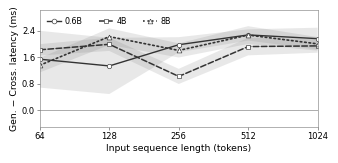

In [60]:
# =========================
# Styling
# =========================


def style_axes(ax):
    ax.set_facecolor("white")
    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.48)
        spine.set_color("0.55")

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=TICK_FS,
        length=2.0,
        width=0.45,
        color="0.35",
        pad=1.5,
    )

    ax.tick_params(
        axis="both",
        which="minor",
        length=0,
    )



# =========================
# Plot
# =========================

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))

style_axes(ax)

for scale in SCALES:
    sub = diff[diff["scale"] == scale].copy()

    sub = sub.sort_values("max_len")

    if sub.empty:
        continue

    xs = sub["max_len"].to_numpy()
    means = sub["latency_diff"].to_numpy()
    stds = sub["latency_diff_std"].to_numpy()

    lower = means - stds
    upper = means + stds

    ax.fill_between(
        xs,
        lower,
        upper,
        facecolor=BAND_COLOR,
        edgecolor="none",
        alpha=BAND_ALPHA,
        zorder=1,
    )

    ax.plot(
        xs,
        means,
        color=LINE_COLOR,
        linestyle=SCALE_STYLE[scale],
        linewidth=SCALE_LINEWIDTH[scale],
        marker=SCALE_MARKER[scale],
        markersize=MARKER_SIZE[scale],
        markerfacecolor="white",
        markeredgecolor=LINE_COLOR,
        markeredgewidth=MARKER_EDGE_WIDTH,
        solid_capstyle="round",
        dash_capstyle="round",
        zorder=2,
        label=SCALE_LABEL[scale],
    )



# =========================
# Axes
# =========================

ax.axhline(
    0,
    color="0.65",
    linewidth=0.65,
    zorder=0,
)

ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(LENS)

ax.set_xticklabels([str(max_len) for max_len in LENS])

ax.set_xlim(
    min(LENS),
    max(LENS),
)

all_lower = diff["latency_diff"] - diff["latency_diff_std"]

all_upper = diff["latency_diff"] + diff["latency_diff_std"]

y_min = min(0, all_lower.min())
y_max = max(0, all_upper.max())

y_range = y_max - y_min
y_padding = max(0.5, 0.08 * y_range)

ax.set_ylim(
    y_min - y_padding,
    y_max + y_padding,
)

ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

ax.set_xlabel(
    "Input sequence length (tokens)",
    fontsize=AXIS_LABEL_FS,
    labelpad=2.5,
)

ax.set_ylabel(
    "Gen. − Cross. latency (ms)",
    fontsize=AXIS_LABEL_FS,
    labelpad=2.0,
)



# =========================
# Legend
# =========================

legend_handles = [
    Line2D(
        [0],
        [0],
        color=LINE_COLOR,
        linestyle=SCALE_STYLE[scale],
        linewidth=SCALE_LINEWIDTH[scale],
        marker=SCALE_MARKER[scale],
        markersize=3.4,
        markerfacecolor="white",
        markeredgecolor=LINE_COLOR,
        markeredgewidth=0.45,
        label=SCALE_LABEL[scale],
    )
    for scale in SCALES
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    ncol=3,
    frameon=False,
    fontsize=LEGEND_FS,
    handlelength=1.8,
    handletextpad=0.40,
    labelspacing=0.28,
    borderaxespad=0.45,
)

# =========================
# Layout and save
# =========================

fig.subplots_adjust(
    left=0.18,
    right=0.985,
    bottom=0.21,
    top=0.97,
)

fig.savefig(
    "figures/oracle_latency_gap_vs_len.pdf",
    bbox_inches="tight",
    pad_inches=0.04,
)

plt.show()